# ¿Quién va a abandonar la carrera? Alerta temprana de deserción
Diplomado en Ciencia de Datos y Análisis Avanzado 2026 · Proyecto Final Integrador

La pregunta: al terminar el primer semestre, ¿qué alumnos tienen riesgo de abandonar la carrera?
Si la institución lo sabe a tiempo, puede ofrecerles tutorías, orientación, un plan de pagos o una beca.

Cómo incorporamos la devolución del profesor:

| Observación del docente | Qué hicimos |
|---|---|
| Los 794 *Matriculados* son una categoría real, no casos "sin etiqueta" | Entran al entrenamiento, dentro del grupo "no desertó". Ver sección 2.1 |
| Definir binario o multiclase | Binario: Desertó vs. resto (graduados + matriculados) |
| Predicción temprana: solo hasta el 1er semestre | Excluimos todas las variables del 2º semestre |
| Recall de Dropout como métrica principal, más PR-AUC | Meta: detectar al menos el 80 % de los desertores. Elegimos el modelo por PR-AUC |

Índice
1. Librerías
2. Carga de datos
   - 2.1 La variable objetivo
3. Calidad de los datos
   - 3.1 Nacionalidad · 3.2 Promedios · 3.3 Carreras · 3.4 Posibles errores de carga
4. Variable objetivo y nuevas variables
5. Relación de las variables con la deserción
6. Ingeniería de variables: resumen de decisiones
7. Selección final de variables
8. División en entrenamiento y prueba
9. Paso 1: modelos con la configuración por defecto
10. Paso 2: ajuste de hiperparámetros
11. Paso 3: ¿cómo funciona la alerta?
12. Paso 4: ¿qué comparamos al final?
   - Champion y Challenger · Variables que más usa el modelo · Diferencias entre modelos · Curva de ganancia · Variables de pago · Matriculados
13. Recall vs. precisión: ¿cuántas falsas alarmas cuesta detectar más?
14. Auditoría por subgrupos
   - Brechas de detección entre grupos
15. ¿Quiénes se escapan? Desertores no detectados
   - Desertores no detectados por carrera · Desertores atípicos
16. ¿Cuánto le cuesta a la institución? Horas de tutoría
17. Posibles soluciones
   - Propuesta de implementación · Piloto e indicadores · Riesgos y límites
18. Experimento: alerta a mitad y al final del 2º semestre
19. Observación: modelo en cascada (descartado)
20. Conclusiones generales

## 1. Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency
import warnings
warnings.filterwarnings("ignore")

## 2. Cargar los datos
Fuente: *Predict Students' Dropout and Academic Success* (UCI, Realinho et al., 2021, CC BY 4.0).
Instituto Politécnico de Portalegre, Portugal. Versión traducida al español provista por la cátedra.

In [2]:
desercion_escolar = pd.read_csv("desercion_escolar_ES.csv")
desercion_escolar.head()

,Estado_civil,Modalidad_de_ingreso,Orden_de_preferencia,Carrera,Turno,Titulacion_previa,Nota_titulacion_previa,Nacionalidad,Nivel_educativo_madre,Nivel_educativo_padre,...,Materias_2S_reconocidas,Materias_2S_inscriptas,Materias_2S_evaluaciones,Materias_2S_aprobadas,Promedio_2S,Materias_2S_sin_evaluacion,Tasa_de_desempleo,Tasa_de_inflacion,PBI,Resultado
0,Soltero/a,2ª fase - contingente general,5,171,Diurno,Educación secundaria,122.0,Portuguesa,Básica 3er ciclo (9°/10°/11°) o equiv.,Otro - 11° año,...,0,0,0,0,0.0,0,10.8,1.4,1.74,Desertó
1,Soltero/a,Estudiante internacional (grado),1,9254,Diurno,Educación secundaria,160.0,Portuguesa,Educación secundaria,Superior - Grado,...,0,6,6,6,13.666.666.666.666.600,0,13.9,-0.3,0.79,Se graduó
2,Soltero/a,1ª fase - contingente general,5,9070,Diurno,Educación secundaria,122.0,Portuguesa,Básica 1er ciclo (4°/5° año) o equiv.,Básica 1er ciclo (4°/5° año) o equiv.,...,0,6,0,0,0.0,0,10.8,1.4,1.74,Desertó
3,Soltero/a,2ª fase - contingente general,2,9773,Diurno,Educación secundaria,122.0,Portuguesa,Básica 2do ciclo (6°/7°/8° año) o equiv.,Básica 1er ciclo (4°/5° año) o equiv.,...,0,6,10,5,12.4,0,9.4,-0.8,-3.12,Se graduó
4,Casado/a,Mayor de 23 años,1,8014,Nocturno,Educación secundaria,100.0,Portuguesa,Básica 1er ciclo (4°/5° año) o equiv.,Básica 2do ciclo (6°/7°/8° año) o equiv.,...,0,6,6,6,13.0,0,13.9,-0.3,0.79,Se graduó


In [3]:
desercion_escolar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Estado_civil                       4424 non-null   object 
 1   Modalidad_de_ingreso               4424 non-null   object 
 2   Orden_de_preferencia               4424 non-null   int64  
 3   Carrera                            4424 non-null   int64  
 4   Turno                              4424 non-null   object 
 5   Titulacion_previa                  4424 non-null   object 
 6   Nota_titulacion_previa             4424 non-null   float64
 7   Nacionalidad                       4424 non-null   object 
 8   Nivel_educativo_madre              4424 non-null   object 
 9   Nivel_educativo_padre              4424 non-null   object 
 10  Ocupacion_madre                    4424 non-null   object 
 11  Ocupacion_padre                    4424 non-null   objec

In [4]:
desercion_escolar.nunique().sort_values()

Turno                                  2
Desplazado                             2
Deudor                                 2
Necesidades_educativas_especiales      2
Estudiante_internacional               2
Becario                                2
Genero                                 2
Matricula_al_dia                       2
Resultado                              3
Estado_civil                           6
Orden_de_preferencia                   8
Tasa_de_inflacion                      9
Materias_2S_sin_evaluacion            10
Tasa_de_desempleo                     10
PBI                                   10
Materias_1S_sin_evaluacion            11
Carrera                               17
Titulacion_previa                     17
Modalidad_de_ingreso                  18
Materias_2S_reconocidas               19
Materias_2S_aprobadas                 20
Nacionalidad                          21
Materias_1S_reconocidas               21
Materias_2S_inscriptas                22
Materias_1S_insc

In [5]:
"""
-El dataset no cuenta con datos nulos
-Cuenta con varios columnas binarias y muchas otras categoricas.
"""

'\n-El dataset no cuenta con datos nulos\n-Cuenta con varios columnas binarias y muchas otras categoricas.\n'

Números de deserción y matriculados.

In [6]:
pd.DataFrame({
    'Conteo': desercion_escolar["Resultado"].value_counts(),
    'Porcentaje (%)': (desercion_escolar["Resultado"].value_counts(normalize=True) * 100).round(2)
})

,Conteo,Porcentaje (%)
Resultado,,
Se graduó,2209,49.93
Desertó,1421,32.12
Matriculado,794,17.95


Necesidades_educativas_especiales

In [7]:
necesidades_especiales = desercion_escolar[desercion_escolar["Necesidades_educativas_especiales"] == "Sí"]
necesidades_especiales.head()

,Estado_civil,Modalidad_de_ingreso,Orden_de_preferencia,Carrera,Turno,Titulacion_previa,Nota_titulacion_previa,Nacionalidad,Nivel_educativo_madre,Nivel_educativo_padre,...,Materias_2S_reconocidas,Materias_2S_inscriptas,Materias_2S_evaluaciones,Materias_2S_aprobadas,Promedio_2S,Materias_2S_sin_evaluacion,Tasa_de_desempleo,Tasa_de_inflacion,PBI,Resultado
42,Soltero/a,1ª fase - contingente general,6,9500,Diurno,Educación secundaria,103.0,Portuguesa,Educación secundaria,Superior - Grado,...,0,8,9,7,14.342.857.142.857.100,0,11.1,0.6,2.02,Se graduó
221,Casado/a,1ª fase - contingente general,4,9853,Diurno,Educación secundaria,134.0,Portuguesa,Básica 1er ciclo (4°/5° año) o equiv.,Básica 1er ciclo (4°/5° año) o equiv.,...,0,6,6,6,14.5,0,10.8,1.4,1.74,Se graduó
237,Soltero/a,2ª fase - contingente general,2,9238,Diurno,Educación secundaria,133.0,Portuguesa,Básica 1er ciclo (4°/5° año) o equiv.,Básica 1er ciclo (4°/5° año) o equiv.,...,0,6,9,6,11.571.428.571.428.500,0,15.5,2.8,-4.06,Se graduó
391,Soltero/a,Mayor de 23 años,1,9500,Diurno,Educación secundaria,150.0,Portuguesa,Educación secundaria,Básica 3er ciclo (9°/10°/11°) o equiv.,...,0,8,13,5,12.14,0,16.2,0.3,-0.92,Matriculado
402,Soltero/a,1ª fase - contingente general,1,9773,Diurno,Educación secundaria,120.0,Portuguesa,Básica 2do ciclo (6°/7°/8° año) o equiv.,Básica 1er ciclo (4°/5° año) o equiv.,...,0,6,11,3,11.0,0,7.6,2.6,0.32,Matriculado


In [8]:
tabla = pd.crosstab(desercion_escolar["Necesidades_educativas_especiales"], desercion_escolar["Resultado"], normalize='index') * 100
print(tabla.round(1))

Resultado                          Desertó  Matriculado  Se graduó
Necesidades_educativas_especiales                                 
No                                    32.1         17.9       50.0
Sí                                    33.3         21.6       45.1


In [9]:
#Aunque el numero de personas con que requirieron una "educacion especial" es minoritaria con 51 alumnos, no se descartara del analisis por ser un dato valido, tal vez con un peso menor pero
#forma parte del analisis.

### 2.1 La variable objetivo

`Resultado` tiene 3 categorías. Según la documentación de UCI, describe la situación al final de la duración normal de la carrera:
- Se graduó: terminó a tiempo.
- Desertó: abandonó.
- Matriculado: sigue cursando cuando ya debería haber terminado (está atrasado). Es un resultado real, no un alumno "sin dato".

Nuestro enfoque para el target será binario: Desertó = 1; Se graduó o Matriculado = 0.

El target de este dataset se centra en predecir el abandono por parte de los estudiantes. Los alumnos que siguen matriculados NO se eliminan ya que dispone de una etiqueta valida, y se optara por un enfoque de deteccion temprana en el primer semestre.

In [10]:
# Los "Matriculado" se mantienen: entran como "no desertó" (target binario Desertó vs. resto).
desercion_escolar = desercion_escolar.copy()

In [11]:
desercion_escolar["Resultado"].unique()

array(['Desertó', 'Se graduó', 'Matriculado'], dtype=object)

- El problema queda planteado como binario: Desertó vs. resto, y los matriculados entran al entrenamiento como "no desertó". Así el modelo aprende de los 4.424 alumnos y se puede aplicar a todos.

## 3. Calidad de los datos
### 3.1 Nacionalidad

Analizaremos la columna nacionalidad para ver si será de utilidad.

In [12]:
desercion_escolar["Nacionalidad"].value_counts()

Nacionalidad
Portuguesa      4314
Brasileña         38
Santotomense      14
Española          13
Caboverdiana      13
Guineana           5
Moldava            3
Italiana           3
Ucraniana          3
Rumana             2
Angoleña           2
Mexicana           2
Mozambiqueña       2
Alemana            2
Rusa               2
Turca              1
Neerlandesa        1
Colombiana         1
Cubana             1
Inglesa            1
Lituana            1
Name: count, dtype: int64

In [13]:
# Como casi todas las nacionalidades tienen muy pocos alumnos (1 a 38), las agrupamos según el idioma:
# lo relevante es si el alumno tiene el portugués como lengua materna (un brasileño o caboverdiano estudia en su idioma).
lusofonas = ["Brasileña", "Caboverdiana", "Santotomense", "Angoleña", "Mozambiqueña", "Guineana"]  # Guineana = Guinea-Bisáu

def agrupar_nacionalidad(valor):
    if valor == "Portuguesa":
        return "Portuguesa"
    elif valor in lusofonas:
        return "Extranjero lusófono"
    else:
        return "Extranjero no lusófono"

desercion_escolar["Nacionalidad_agrupada"] = desercion_escolar["Nacionalidad"].apply(agrupar_nacionalidad)

# % de cada resultado según el grupo de nacionalidad
print((pd.crosstab(desercion_escolar["Nacionalidad_agrupada"], desercion_escolar["Resultado"], normalize="index") * 100).round(1))
desercion_escolar["Nacionalidad_agrupada"].value_counts()

Resultado               Desertó  Matriculado  Se graduó
Nacionalidad_agrupada                                  
Extranjero lusófono        28.4         18.9       52.7
Extranjero no lusófono     30.6         27.8       41.7
Portuguesa                 32.2         17.8       50.0


Nacionalidad_agrupada
Portuguesa                4314
Extranjero lusófono         74
Extranjero no lusófono      36
Name: count, dtype: int64

- La columna `Nacionalidad` se mantiene y se agrega `Nacionalidad_agrupada` (Portuguesa / Extranjero lusófono / Extranjero no lusófono). Los no lusófonos muestran más rezago (más "Matriculado"), aunque son pocos alumnos (36) y hay que tomarlo con cautela.

### 3.2 Promedios

Ahora revisaremos la calidad de los promedios.

In [14]:
# Las columnas Promedio_1S y Promedio_2S están como texto (object), no como número.
print ("Tipo de dato Promedio 2S: ", desercion_escolar["Promedio_2S"].dtype)
print ("Tipo de dato Promedio 1S: ", desercion_escolar["Promedio_1S"].dtype)

Tipo de dato Promedio 2S:  object
Tipo de dato Promedio 1S:  object


In [15]:
#Se detectan errores de carga.
print ("Valores de promedio 2S", desercion_escolar["Promedio_2S"].unique())
print (90*"*")
print ("Valores de promedio 1S", desercion_escolar["Promedio_1S"].unique())

Valores de promedio 2S ['0.0' '13.666.666.666.666.600' '12.4' '13.0' '11.5' '14.345'
 '14.142.857.142.857.100' '13.5' '14.2' '13.214.285.714.285.700' '11.0'
 '12.0' '14.545' '12.25' '11.425' '12.857.142.857.142.800'
 '12.285.714.285.714.200' '14.114.285.714.285.700'
 '13.285.714.285.714.200' '12.333.333.333.333.300'
 '13.716.666.666.666.600' '10.571.428.571.428.500' '13.4' '14.375'
 '13.428.571.428.571.400' '10.0' '11.6' '15.8' '14.342.857.142.857.100'
 '13.8' '14.333.333.333.333.300' '13.2' '13.771.428.571.428.500'
 '12.833.333.333.333.300' '14.166.666.666.666.600'
 '11.833.333.333.333.300' '13.595' '12.9' '14.935'
 '12.221.428.571.428.500' '12.428.571.428.571.400' '10.75' '10.8' '13.75'
 '10.857.142.857.142.800' '13.333.333.333.333.300'
 '15.055.555.555.555.500' '11.666.666.666.666.600' '12.2' '13.3'
 '11.333.333.333.333.300' '13.08' '11.2' '13.25' '1.447.777.777.777.770'
 '1.423.076.923.076.920' '12.272.727.272.727.200' '12.3' '15.0' '12.8'
 '12.571.428.571.428.500' '12.516.666.666.

In [16]:
# Coreccion de formato en los puntos decimales, sacamos todos los puntos y ponemos la coma donde el número quede en la escala 0-20.
def corregir_promedio(valor):
    texto = str(valor).strip()
    digitos = texto.replace(".", "")
    if digitos.strip("0") == "":                         
        return 0.0
    if texto.count(".") <= 1 and float(texto) <= 20:     
        return float(texto)
    con_dos = float(digitos[:2] + "." + digitos[2:])     # probamos con 2 dígitos enteros (ej. 13,67)
    return con_dos if con_dos <= 20 else float(digitos[:1] + "." + digitos[1:])   # si no, con 1 (ej. 9,8)

for col in ['Promedio_1S', 'Promedio_2S']:
    desercion_escolar[col] = desercion_escolar[col].map(corregir_promedio).round().astype(int)   # redondeado a número entero

- Se redondean los promedios a número entero, en la escala 0-20.

In [17]:
# Verificamos que la reparación funcionó: los promedios ya deberían ser números enteros
print ("Tipo de dato Promedio 2S: ", desercion_escolar["Promedio_2S"].dtype)
print ("Tipo de dato Promedio 1S: ", desercion_escolar["Promedio_1S"].dtype)

print ("Valores de promedio 2S", desercion_escolar["Promedio_2S"].unique())
print (90*"*")
print ("Valores de promedio 1S", desercion_escolar["Promedio_1S"].unique())

Tipo de dato Promedio 2S:  int64
Tipo de dato Promedio 1S:  int64
Valores de promedio 2S [ 0 14 12 13 11 15 10 16 18 17 19]
******************************************************************************************
Valores de promedio 1S [ 0 14 13 12 11 10 15 17 16 18 19]


In [18]:
print(desercion_escolar.dtypes.astype(str).sort_values())

PBI                                  float64
Tasa_de_inflacion                    float64
Tasa_de_desempleo                    float64
Nota_titulacion_previa               float64
Nota_de_admision                     float64
Materias_2S_evaluaciones               int64
Materias_1S_inscriptas                 int64
Materias_1S_evaluaciones               int64
Materias_1S_aprobadas                  int64
Promedio_1S                            int64
Materias_1S_sin_evaluacion             int64
Materias_2S_reconocidas                int64
Materias_1S_reconocidas                int64
Edad_al_matricularse                   int64
Materias_2S_aprobadas                  int64
Promedio_2S                            int64
Materias_2S_sin_evaluacion             int64
Carrera                                int64
Orden_de_preferencia                   int64
Materias_2S_inscriptas                 int64
Estado_civil                          object
Becario                               object
Resultado 

### 3.3 Carreras

In [19]:
carreras_dict_es = {
    33: "Tecnologías de Producción de Biocombustibles", 171: "Diseño de Animación y Multimedia",
    8014: "Servicio Social", 9003: "Agronomía", 9070: "Diseño de Comunicación",
    9085: "Enfermería Veterinaria", 9119: "Ingeniería Informática", 9130: "Equinicultura",
    9147: "Gestión", 9238: "Servicio Social", 9254: "Turismo", 9500: "Enfermería",
    9556: "Higiene Bucal", 9670: "Publicidad y Gestión de Marketing",
    9773: "Periodismo y Comunicación", 9853: "Educación Básica", 9991: "Gestión"
}

desercion_escolar["Carrera"] = desercion_escolar["Carrera"].map(carreras_dict_es)

In [20]:
# Tabla directa con groupby, sin pasar por crosstab + rename
# El total de alumnos incluye a los Matriculados
tabla_carreras = desercion_escolar.groupby("Carrera")["Resultado"].value_counts().unstack(fill_value=0)
tabla_carreras = tabla_carreras.rename(columns={"Desertó": "Desertores", "Se graduó": "Egresados", "Matriculado": "Matriculados"})[["Egresados", "Matriculados", "Desertores"]]

tabla_carreras["Cantidad_alumnos"] = tabla_carreras["Egresados"] + tabla_carreras["Matriculados"] + tabla_carreras["Desertores"]
tabla_carreras["Porcentaje_desercion"] = (tabla_carreras["Desertores"] / tabla_carreras["Cantidad_alumnos"] * 100).round(1)

tabla_carreras = tabla_carreras[["Cantidad_alumnos", "Desertores", "Matriculados", "Egresados", "Porcentaje_desercion"]].sort_values("Porcentaje_desercion", ascending=False)
tabla_carreras

Resultado,Cantidad_alumnos,Desertores,Matriculados,Egresados,Porcentaje_desercion
Carrera,,,,,
Tecnologías de Producción de Biocombustibles,12,8,3,1,66.7
Equinicultura,141,78,21,42,55.3
Ingeniería Informática,170,92,64,14,54.1
Educación Básica,192,85,50,57,44.3
Gestión,648,270,162,216,41.7
Agronomía,210,86,37,87,41.0
Higiene Bucal,86,33,17,36,38.4
Turismo,252,96,41,115,38.1
Diseño de Animación y Multimedia,215,82,37,96,38.1


In [21]:
# Colores para los gráficos (los mismos en todo el notebook)
NARANJA, AZUL, VERDE, GRIS = "#eb6834", "#2a78d6", "#1baf7a", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#ecebe7", "axes.titleweight": "bold", "axes.titlesize": 12, "axes.edgecolor": "#c9c8c2"})

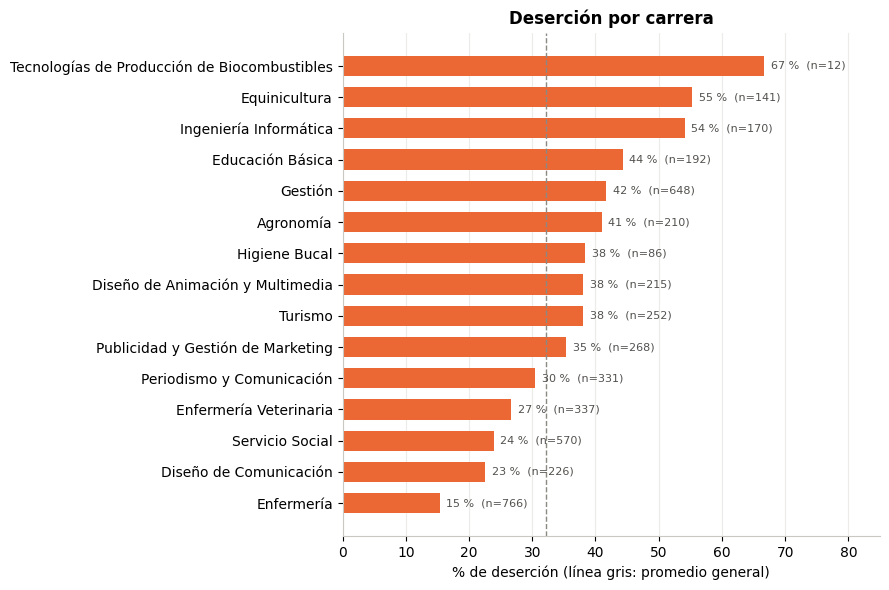

In [22]:
# Gráfico: % de deserción por carrera (incluye matriculados en el total)
tabla_grafico = tabla_carreras.sort_values("Porcentaje_desercion")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(tabla_grafico.index, tabla_grafico["Porcentaje_desercion"], color=NARANJA, height=0.65)
for i, (v, n) in enumerate(zip(tabla_grafico["Porcentaje_desercion"], tabla_grafico["Cantidad_alumnos"])):
    ax.text(v + 1, i, f"{v:.0f} %  (n={n})", va="center", fontsize=8, color="#52514e")
ax.axvline(desercion_escolar["Resultado"].eq("Desertó").mean() * 100, color=GRIS, ls="--", lw=1)  # promedio general
ax.set_xlim(0, 85); ax.set_xlabel("% de deserción (línea gris: promedio general)")
ax.set_title("Deserción por carrera"); ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- La deserción cambia mucho según la carrera. En Equinicultura e Ingeniería Informática abandona más de la mitad de los alumnos, mientras que en Enfermería solo 1 de cada 7. Biocombustibles tiene el valor más alto (67 %), pero son solo 12 alumnos y no es un dato confiable. Las carreras con más abandono son candidatas a revisar su primer año.

In [23]:
desercion_escolar["Carrera"]

0       Diseño de Animación y Multimedia
1                                Turismo
2                 Diseño de Comunicación
3              Periodismo y Comunicación
4                        Servicio Social
                      ...               
4419           Periodismo y Comunicación
4420           Periodismo y Comunicación
4421                          Enfermería
4422                             Gestión
4423           Periodismo y Comunicación
Name: Carrera, Length: 4424, dtype: object

### 3.4 Posibles errores de carga
Revisamos si hay datos imposibles o que no cierran entre sí (idea del trabajo de Mati).

In [24]:
# Revisamos posibles errores de carga (idea del trabajo de Mati): datos imposibles o que no cierran entre sí
d = desercion_escolar
controles = {
    "Edad fuera de 15 a 80 años": ~d["Edad_al_matricularse"].between(15, 80),
    "Nota de admisión fuera de 0 a 200": ~d["Nota_de_admision"].between(0, 200),
    "Promedio 1S fuera de 0 a 20": ~d["Promedio_1S"].between(0, 20),
    "Promedio 2S fuera de 0 a 20": ~d["Promedio_2S"].between(0, 20),
    "1S: más materias aprobadas que inscriptas": d["Materias_1S_aprobadas"] > d["Materias_1S_inscriptas"],
    "1S: más materias sin evaluación que inscriptas": d["Materias_1S_sin_evaluacion"] > d["Materias_1S_inscriptas"],
    "2S: más materias aprobadas que inscriptas": d["Materias_2S_aprobadas"] > d["Materias_2S_inscriptas"],
    "2S: más materias sin evaluación que inscriptas": d["Materias_2S_sin_evaluacion"] > d["Materias_2S_inscriptas"],
}
pd.Series({nombre: condicion.sum() for nombre, condicion in controles.items()}).to_frame("Alumnos con el problema")


,Alumnos con el problema
Edad fuera de 15 a 80 años,0
Nota de admisión fuera de 0 a 200,0
Promedio 1S fuera de 0 a 20,0
Promedio 2S fuera de 0 a 20,0
1S: más materias aprobadas que inscriptas,0
1S: más materias sin evaluación que inscriptas,0
2S: más materias aprobadas que inscriptas,0
2S: más materias sin evaluación que inscriptas,3


- No aparecen datos imposibles en lo que usa el modelo. Los únicos casos raros son 3 alumnos del 2º semestre con más materias sin evaluación que inscriptas, y esas variables no entran al modelo.

## 4. Variable objetivo y nuevas variables

Variable objetivo y correlacion

In [25]:
# 3. Crear el target binario: Desertó = 1, resto (Se graduó + Matriculado) = 0
desercion_escolar["target"] = (desercion_escolar["Resultado"] == "Desertó").astype(int)
desercion_escolar.value_counts("target")

target
0    3003
1    1421
Name: count, dtype: int64

Creacion de nuevas Features

In [26]:
#Features numericas

# Antes combinábamos 1S y 2S (Promedio_general, Tasa_aprobacion_general), pero el 2º semestre no sera tenido en cuenta para la deteccion temprana de deserción, ya que el modelo usa solo información hasta el 1er semestre.

# Tasa de aprobación por semestre (la del 2S se calcula solo para el análisis descriptivo, no entra al modelo)
#si el alumno no tiene materias inscriptas la tasa vale 0 (antes quedaba NaN y después se borraban esas filas)
desercion_escolar["Tasa_aprobacion_1S"] = (desercion_escolar["Materias_1S_aprobadas"] / desercion_escolar["Materias_1S_inscriptas"].replace(0, np.nan)).fillna(0)
desercion_escolar["Tasa_aprobacion_2S"] = (desercion_escolar["Materias_2S_aprobadas"] / desercion_escolar["Materias_2S_inscriptas"].replace(0, np.nan)).fillna(0)

# Materias reconocidas (solo 1er semestre)
desercion_escolar["Tiene_materias_reconocidas"] = (desercion_escolar["Materias_1S_reconocidas"] > 0).astype(int)

In [27]:
# Hay 180 alumnos con 0 materias inscriptas. Son TODOS de "Diseño de Animación y Multimedia" y 75 de ellos se graduaron,
# así que no es que no cursaron: falta la carga de datos de esa carrera. En vez de borrarlos, los marcamos.
desercion_escolar["Sin_datos_academicos"] = (desercion_escolar["Materias_1S_inscriptas"] == 0).astype(int)
print(desercion_escolar.loc[desercion_escolar["Sin_datos_academicos"] == 1, "Carrera"].value_counts())
print(pd.crosstab(desercion_escolar["Sin_datos_academicos"], desercion_escolar["Resultado"]))

Carrera
Diseño de Animación y Multimedia    180
Name: count, dtype: int64
Resultado             Desertó  Matriculado  Se graduó
Sin_datos_academicos                                 
0                        1344          766       2134
1                          77           28         75


- Las variables del modelo usan solo el 1er semestre (`Tasa_aprobacion_1S`, `Promedio_1S`) para evitar que el modelo detecte los abandonos y para crear un sistema de alerta temprana.
Además, los 180 alumnos sin materias inscriptas ya no se borran: se marcan con `Sin_datos_academicos`, porque son un problema de carga de una carrera y no alumnos que no cursaron.

In [28]:
#Creacion features categoricas

print ("Madre: ", desercion_escolar["Nivel_educativo_madre"].unique())

print (70*"*")

print ("Padre: ", desercion_escolar["Nivel_educativo_padre"].unique())

Madre:  ['Básica 3er ciclo (9°/10°/11°) o equiv.' 'Educación secundaria'
 'Básica 1er ciclo (4°/5° año) o equiv.'
 'Básica 2do ciclo (6°/7°/8° año) o equiv.' 'Superior - Grado'
 'Superior - Maestría' 'Técnico superior profesional'
 'Superior - Licenciatura (grado corto)' 'Desconocido' 'Otro - 11° año'
 'Superior - grado (1er ciclo)' '12° año no completado'
 'Superior - Doctorado' 'Especialización tecnológica' '7° año (antiguo)'
 'Estudios superiores especializados' '8° año de escolaridad' '10° año'
 'No sabe leer ni escribir' 'Sabe leer sin 4° año completado'
 'Cursando educación superior' '11° año no completado'
 '9° año no completado' 'Superior - maestría (2do ciclo)'
 'Curso general de comercio' 'Curso técnico-profesional'
 '2° ciclo curso general secundaria' '7° año de escolaridad'
 'Superior - doctorado (3er ciclo)']
**********************************************************************
Padre:  ['Otro - 11° año' 'Superior - Grado'
 'Básica 1er ciclo (4°/5° año) o equiv.'
 'Básica 

In [29]:
#Reducimos a 3 categorias dentro de la feature Nivel_educativo_madre y Nivel_educativo_padre

# Nivel educativo: de ~30 categorías puntuales a 4 niveles generales
def agrupar_nivel_educativo(valor):
    if pd.isna(valor):
        return valor
    valor = str(valor)
    if "Superior" in valor or "superior" in valor:
        return "Superior"
    elif "12°" in valor or "11°" in valor or "10°" in valor or "secundaria" in valor.lower():
        return "Secundaria"
    elif "No sabe leer" in valor or "Desconocido" in valor:
        return "Sin_datos"
    else:
        return "Basica"

desercion_escolar["Nivel_educativo_madre_agrupado"] = desercion_escolar["Nivel_educativo_madre"].apply(agrupar_nivel_educativo)
desercion_escolar["Nivel_educativo_padre_agrupado"] = desercion_escolar["Nivel_educativo_padre"].apply(agrupar_nivel_educativo)

In [30]:
#Combinar ambas features de nivel educativo de padre y madre.

# Nivel educativo máximo entre ambos padres (en vez de dos columnas separadas)
orden_nivel = {"Sin_datos": 0, "Basica": 1, "Secundaria": 2, "Superior": 3}
desercion_escolar["Nivel_educativo_max_padres"] = desercion_escolar.apply(
    lambda fila: max(
        orden_nivel.get(fila["Nivel_educativo_madre_agrupado"], 0),
        orden_nivel.get(fila["Nivel_educativo_padre_agrupado"], 0)
    ), axis=1
)
# Ojo: esto sale numérico (0-3), no categórico -- es ordinal real, tiene sentido dejarlo así

## 5. Relación de las variables con la deserción

In [31]:
### Grupo numericos ###

numericas = [
    "Tasa_aprobacion_1S",         # solo 1er semestre
    "Promedio_1S",                # solo 1er semestre
    "Materias_1S_aprobadas",      # cantidad de materias aprobadas en el 1S
    "Tiene_materias_reconocidas",
    "Sin_datos_academicos",       # bandera de alumnos sin registro académico (ver arriba)
    "Nota_de_admision", "Nota_titulacion_previa",     # se mantienen separadas 
    "Edad_al_matricularse",
    "Orden_de_preferencia",
    "Nivel_educativo_max_padres"  # ordinal (0-3), se deja numérica
]
# Indice_macro / Tasa_de_desempleo / PBI / Tasa_de_inflacion quedan afuera:
# ya sabíamos por el heatmap que su correlación con target era ~0.00-0.05, casi nula
corr_matrix = desercion_escolar[numericas + ["target"]].corr()

In [32]:
desercion_escolar["Genero"].unique()

array(['Masculino', 'Femenino'], dtype=object)

In [33]:
desercion_escolar["Turno"].unique()

array(['Diurno', 'Nocturno'], dtype=object)

In [34]:
desercion_escolar["Becario"].unique()

array(['No', 'Sí'], dtype=object)

In [35]:
### Grupo categoricos ###

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.sum().sum()
    r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Se incluyen Matricula_al_dia, Deudor y Desplazado (Matricula_al_dia es de las más fuertes)
# y la Nacionalidad_agrupada que mantuvimos.
categoricas = ["Estado_civil", "Genero", "Carrera", "Turno", "Titulacion_previa", "Modalidad_de_ingreso", "Becario",
               "Matricula_al_dia", "Deudor", "Desplazado", "Nacionalidad_agrupada"]


resultados_cramer = {col: cramers_v(desercion_escolar[col], desercion_escolar["target"]) for col in categoricas}
pd.Series(resultados_cramer).sort_values(ascending=False)

Matricula_al_dia         0.428403
Modalidad_de_ingreso     0.300360
Carrera                  0.245985
Becario                  0.244794
Deudor                   0.228645
Titulacion_previa        0.214009
Genero                   0.203476
Estado_civil             0.115918
Desplazado               0.106746
Turno                    0.079723
Nacionalidad_agrupada    0.010919
dtype: float64

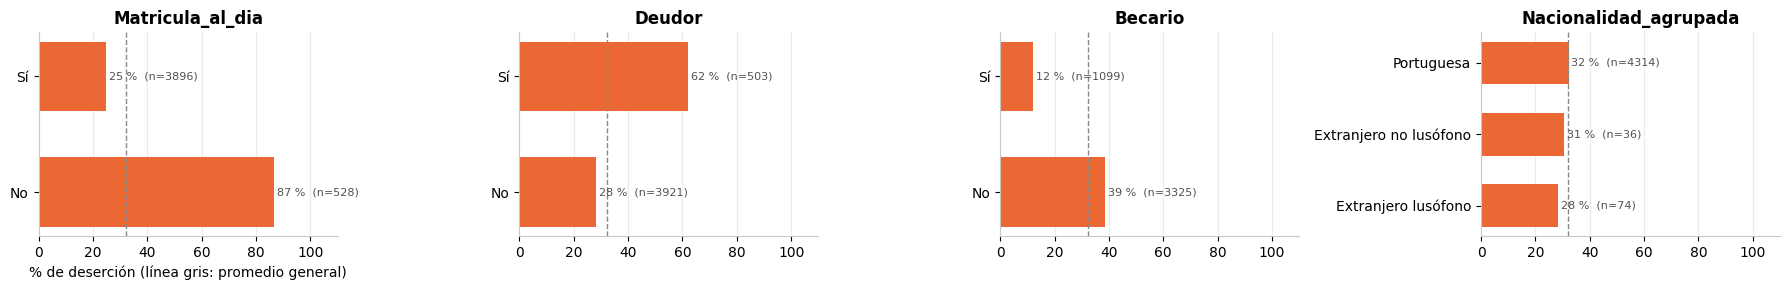

In [36]:
# Gráfico: % de deserción según la situación económica y la nacionalidad agrupada
fig, axes = plt.subplots(1, 4, figsize=(18, 3))
for ax, col in zip(axes, ["Matricula_al_dia", "Deudor", "Becario", "Nacionalidad_agrupada"]):
    t = desercion_escolar.groupby(col)["target"].agg(["mean", "size"])
    ax.barh(t.index.astype(str), t["mean"] * 100, color=NARANJA, height=0.6)
    for i, (v, n) in enumerate(zip(t["mean"] * 100, t["size"])):
        ax.text(v + 1, i, f"{v:.0f} %  (n={n})", va="center", fontsize=8, color="#52514e")
    ax.axvline(desercion_escolar["target"].mean() * 100, color=GRIS, ls="--", lw=1)
    ax.set_xlim(0, 110); ax.set_title(col); ax.grid(axis="y", visible=False)
axes[0].set_xlabel("% de deserción (línea gris: promedio general)")
plt.tight_layout()
plt.show()
# La matrícula impaga es la señal económica más fuerte: casi 9 de cada 10 abandonan.

- Con la matrícula impaga abandona el 87 % de los alumnos (con la cuota al día, el 25 %), y entre los deudores el 62 %. La beca funciona como protección: abandona el 12 % de los becarios contra el 39 % del resto. La nacionalidad, en cambio, casi no cambia la tasa de abandono.
Importante tasa de abandono segun el impago de matricula. Aunque sea una institucion publica y el costo sea significativamente menor a una privada, se debera abordar que otras variables influyen entre el impago y el abandono.

In [37]:
corr_tasas = desercion_escolar[["Tasa_aprobacion_1S", "Tasa_aprobacion_2S"]].corr().iloc[0, 1]
print("Correlación entre las dos tasas:", round(corr_tasas, 3))

Correlación entre las dos tasas: 0.873


Resumen de nuevas features

Tasa_aprobacion_1S = Materias_1S_aprobadas / Materias_1S_inscriptas (0 si no tiene materias inscriptas)

Tasa_aprobacion_2S = Materias_2S_aprobadas / Materias_2S_inscriptas (solo para el análisis, no entra al modelo)

Sin_datos_academicos = 1 si el alumno no tiene materias cargadas (180 alumnos de Diseño de Animación y Multimedia)

Nacionalidad_agrupada = Portuguesa / Extranjero lusófono / Extranjero no lusófono

--------------------------------------------------------------------------------------------------------
Nivel_educativo_max_padres = Máximo nivel educativo entre Nivel_educativo_madre y Nivel_educativo_padre,
tras agruparlos en 4 categorías ordinales (Sin_datos=0, Basica=1, Secundaria=2, Superior=3)

Barras (V de Cramér):

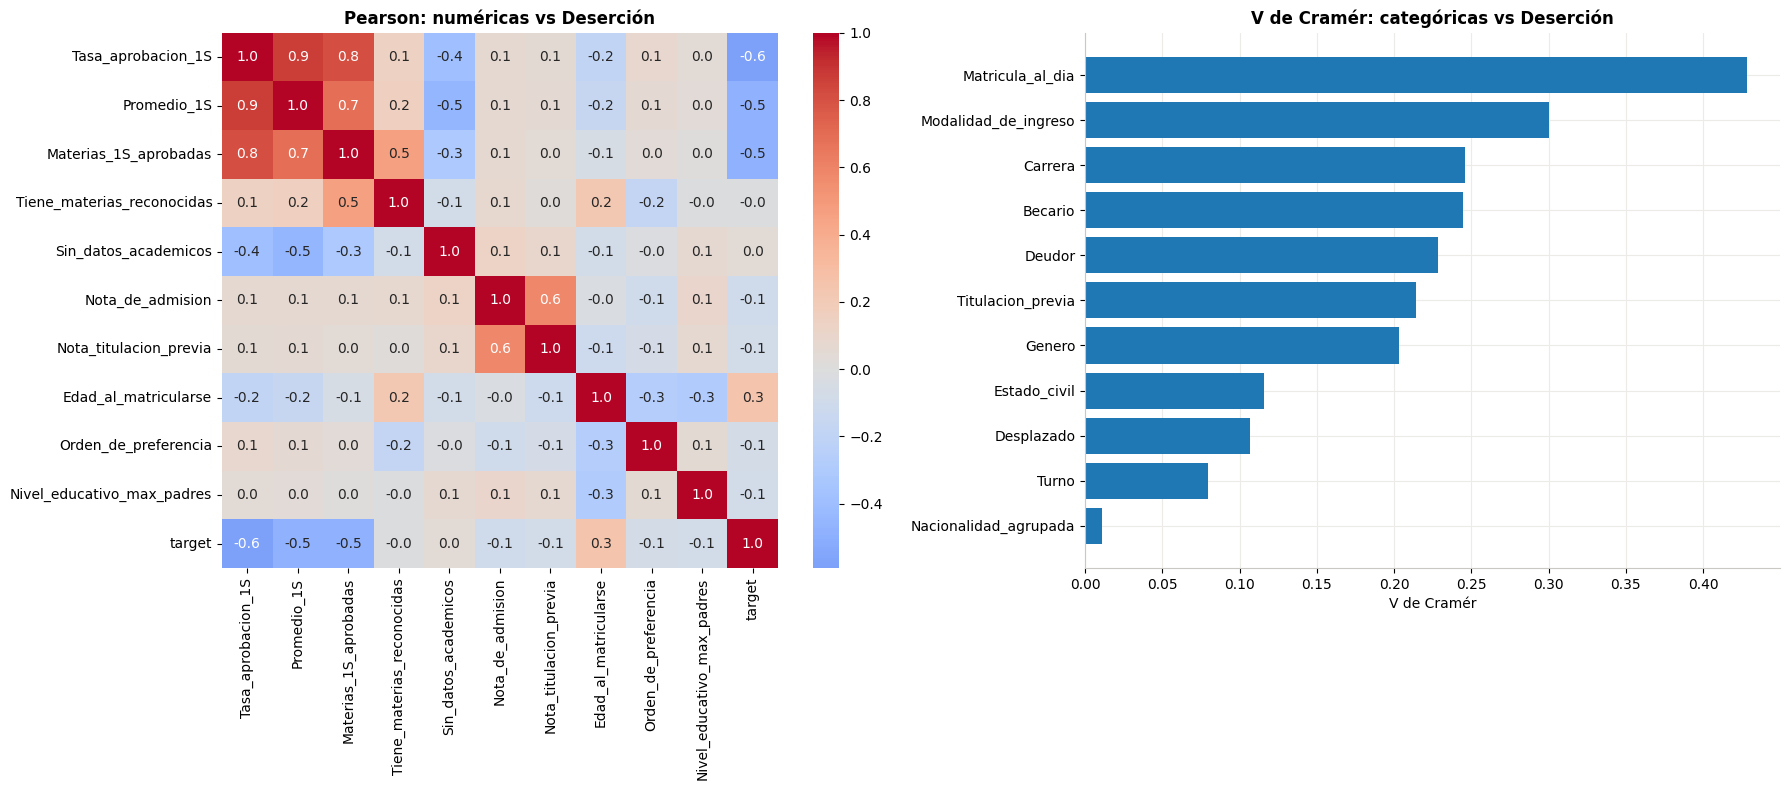

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".1f", ax=axes[0])
axes[0].set_title("Pearson: numéricas vs Deserción")

serie_cramer = pd.Series(resultados_cramer).sort_values(ascending=True)
axes[1].barh(serie_cramer.index, serie_cramer.values)
axes[1].set_title("V de Cramér: categóricas vs Deserción")
axes[1].set_xlabel("V de Cramér")

plt.tight_layout()
plt.show()

- El rendimiento del 1er semestre es la señal más clara: de los alumnos que no aprueban ninguna materia abandona el 92 %, y de los que aprueban todas solo el 9 %. Después vienen la situación de pago, la vía de ingreso y la carrera.
También influyen la edad y el género: entre quienes entran con 20 años o menos abandona el 21 %, y entre los mayores de 23 más de la mitad (muchos estudian mientras trabajan). Los hombres abandonan casi el doble que las mujeres (45 % contra 25 %).

## 6. Ingeniería de variables: resumen de decisiones

In [39]:
"""
Se redujeron variables redundantes (alta correlación por construcción) agrupándolas en tasas:

-`Materias_1S_aprobadas` y sus columnas de embudo (inscriptas/evaluaciones/sin evaluación) → `Tasa_aprobacion_1S`;
-`Materias_1S_reconocidas` → `Tiene_materias_reconocidas` (binaria); `Nivel_educativo_madre`/`_padre` (~30 categorías c/u) → `Nivel_educativo_max_padres` (ordinal 0-3).

Solo se usa información del 1er semestre (pedido del profesor). El 2º semestre queda fuera del modelo.
Los Matriculados se mantienen como "no desertó" (target binario Desertó vs. resto).
Nacionalidad se mantiene, agrupada por idioma (`Nacionalidad_agrupada`).

Se descartaron por correlación/asociación nula con `target`: `Tasa_de_desempleo`, `Tasa_de_inflacion`, `PBI` (Pearson ~0.00-0.05) y `Necesidades_educativas_especiales`,
`Estudiante_internacional` (V de Cramér ~0.004).

`Carrera` se tradujo de código numérico a nombre en español, unificando duplicados por turno (Servicio Social, Gestión).

La selección final de variables se hizo por umbral estadístico (Pearson / V de Cramér), no por desempeño del modelo, para evitar sesgo de ajuste al test.
Esa selección se calcula solo con los datos de entrenamiento. `target` se excluye de las features y el split train/test es estratificado, evitando fuga de información.
"""

'\nSe redujeron variables redundantes (alta correlación por construcción) agrupándolas en tasas:\n\n-`Materias_1S_aprobadas` y sus columnas de embudo (inscriptas/evaluaciones/sin evaluación) → `Tasa_aprobacion_1S`;\n-`Materias_1S_reconocidas` → `Tiene_materias_reconocidas` (binaria); `Nivel_educativo_madre`/`_padre` (~30 categorías c/u) → `Nivel_educativo_max_padres` (ordinal 0-3).\n\nSolo se usa información del 1er semestre (pedido del profesor). El 2º semestre queda fuera del modelo.\nLos Matriculados se mantienen como "no desertó" (target binario Desertó vs. resto).\nNacionalidad se mantiene, agrupada por idioma (`Nacionalidad_agrupada`).\n\nSe descartaron por correlación/asociación nula con `target`: `Tasa_de_desempleo`, `Tasa_de_inflacion`, `PBI` (Pearson ~0.00-0.05) y `Necesidades_educativas_especiales`,\n`Estudiante_internacional` (V de Cramér ~0.004).\n\n`Carrera` se tradujo de código numérico a nombre en español, unificando duplicados por turno (Servicio Social, Gestión).\n\nL

## 7. Selección final de variables
Usamos solo las variables que muestran relación con la deserción:
- numéricas con correlación de Pearson mayor a 0,1 (en valor absoluto);
- categóricas con V de Cramér mayor a 0,1.

Esta selección se calcula solo con los datos de entrenamiento, para que el test no influya en ninguna decisión.

In [40]:
from sklearn.model_selection import train_test_split

# La selección de variables se calcula solo con el entrenamiento, para que el test no influya.
# Usamos exactamente el mismo split que en la celda siguiente (test 20 %, estratificado, semilla 42).
idx_train, idx_test = train_test_split(desercion_escolar.index, test_size=0.2, stratify=desercion_escolar["target"], random_state=42)
datos_train = desercion_escolar.loc[idx_train]

# Numéricas: correlación absoluta con el target por encima de un umbral
umbral_num = 0.1
seleccion_numericas = datos_train[numericas + ["target"]].corr()["target"].drop("target")
seleccion_numericas = seleccion_numericas[seleccion_numericas.abs() > umbral_num].index.tolist()

# Categóricas: V de Cramér por encima de un umbral
umbral_cat = 0.1
cramer_train = pd.Series({col: cramers_v(datos_train[col], datos_train["target"]) for col in categoricas})
seleccion_categoricas = cramer_train[cramer_train > umbral_cat].index.tolist()

print("Numéricas seleccionadas:", seleccion_numericas)
print("Categóricas seleccionadas:", seleccion_categoricas)

features_finales = seleccion_numericas + seleccion_categoricas
df_modelo = desercion_escolar[features_finales + ["target"]]  # Ya no hace falta dropna (las tasas sin materias valen 0), así no se pierden alumnos
print("Filas antes:", len(desercion_escolar), "| Filas en df_modelo:", len(df_modelo))

Numéricas seleccionadas: ['Tasa_aprobacion_1S', 'Promedio_1S', 'Materias_1S_aprobadas', 'Edad_al_matricularse']
Categóricas seleccionadas: ['Estado_civil', 'Genero', 'Carrera', 'Titulacion_previa', 'Modalidad_de_ingreso', 'Becario', 'Matricula_al_dia', 'Deudor', 'Desplazado']
Filas antes: 4424 | Filas en df_modelo: 4424


## 8. División en entrenamiento y prueba
- 80 % entrenamiento: con estos alumnos el modelo aprende y elegimos hiperparámetros y umbral.
- 20 % prueba (test): 885 alumnos que el modelo nunca ve mientras aprende. Se usan al final, una sola vez, como un examen.

Es estratificado: los dos conjuntos tienen la misma proporción de desertores (32 %).

In [41]:
# Mismo split que se usó para seleccionar variables (20 % test, estratificado, semilla 42)
X = df_modelo.drop(columns=["target"])
y = df_modelo["target"]  # 1 = Desertó, 0 = Se graduó o Matriculado

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción train:", y_train.value_counts(normalize=True).to_dict())
print("Proporción test:", y_test.value_counts(normalize=True).to_dict())

assert set(X_train.index) == set(idx_train)

Train: (3539, 13) | Test: (885, 13)
Proporción train: {0: 0.6787228030517095, 1: 0.3212771969482905}
Proporción test: {0: 0.6790960451977401, 1: 0.32090395480225986}


In [42]:
# Control de filtración de datos (idea del trabajo de los compañeros)
prohibidas = ["Resultado", "target"] + [c for c in desercion_escolar.columns if "_2S" in c]
filtradas = [c for c in X.columns if c in prohibidas]

assert not filtradas, f"Variables no permitidas en el modelo: {filtradas}"
assert set(X_train.index).isdisjoint(X_test.index), "Hay alumnos repetidos entre entrenamiento y prueba"
assert len(X_train) + len(X_test) == len(X), "Se perdieron alumnos en la división"
print("Control superado: el modelo no usa el resultado ni variables del 2º semestre, y entrenamiento y prueba no comparten alumnos.")

Control superado: el modelo no usa el resultado ni variables del 2º semestre, y entrenamiento y prueba no comparten alumnos.


## 9. Paso 1: modelos con la configuración por defecto
Probamos varios algoritmos tal como vienen: sin ajustar hiperparámetros y con el umbral estándar de 0,5
(el alumno queda marcado si el modelo le da 50 % o más de probabilidad de abandonar).
Este es el punto de partida, el "antes", contra el que después comparamos.

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.svm import SVC
# XGBoost y CatBoost pueden no estar instalados (CatBoost no viene en Colab).
# Si no están, se saltean. En Colab: !pip install catboost
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None

# --- 1. Preprocesamiento: numéricas se escalan, categóricas se codifican ---
numericas_en_X = [c for c in seleccion_numericas if c in X_train.columns]
categoricas_en_X = [c for c in seleccion_categoricas if c in X_train.columns]

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), numericas_en_X),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categoricas_en_X)
])

# --- 2. Modelos a comparar ---
modelos = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),  # probability=True es necesario para predict_proba (más lento de entrenar)
}
if XGBClassifier is not None:
    modelos["XGBoost"] = XGBClassifier(random_state=42, eval_metric="logloss")
if CatBoostClassifier is not None:
    modelos["CatBoost"] = CatBoostClassifier(random_state=42, verbose=0)  # verbose=0 para que no imprima cada iteración


# --- 3. Entrenar cada modelo dentro de un Pipeline y calcular métricas ---
resultados = []
for nombre, modelo in modelos.items():
    pipeline = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba)   # AGREGADO: métrica pedida por el profesor
    })

# --- 4. Tabla comparativa final ---
tabla_resultados = pd.DataFrame(resultados).set_index("Modelo").round(3)
print(tabla_resultados)

                     Accuracy  Precision  Recall     F1  AUC-ROC  PR-AUC
Modelo                                                                  
Regresión Logística     0.862      0.840   0.704  0.766    0.903   0.867
Random Forest           0.847      0.802   0.697  0.746    0.896   0.852
Gradient Boosting       0.858      0.821   0.711  0.762    0.910   0.872
SVM                     0.855      0.861   0.655  0.744    0.897   0.863
XGBoost                 0.845      0.795   0.697  0.743    0.891   0.851
CatBoost                0.864      0.842   0.711  0.771    0.909   0.873


- Se agrega PR-AUC, la métrica que pidió el profesor junto al Recall de Dropout. XGBoost y CatBoost se importan solo si están instalados: en Colab CatBoost no viene por defecto y el notebook se cortaba en esta celda.

## 10. Paso 2: ajuste de hiperparámetros
Los hiperparámetros son las "perillas" de cada algoritmo que no se aprenden de los datos y hay que elegir. Por ejemplo:
- la cantidad de árboles de un Random Forest;
- la profundidad máxima de cada árbol;
- cuánto se penaliza la complejidad en la regresión logística.

Cómo los elegimos:
1. Para cada algoritmo definimos varias combinaciones posibles.
2. Cada combinación se prueba con validación cruzada de 5 partes sobre el entrenamiento: se entrena con 4 partes y se evalúa con la 5ª, rotando las 5 veces.
3. Nos quedamos con la combinación de mejor PR-AUC promedio.

El test no se usa en ningún momento de este paso.

In [44]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # 5 partes, misma proporción de desertores en cada una

# Hiperparámetros a probar en cada modelo
busquedas = {
    "Regresión Logística": (LogisticRegression(max_iter=3000, random_state=42),
                            {"modelo__C": [0.01, 0.1, 1, 10], "modelo__class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(random_state=42, n_jobs=1),
                      {"modelo__n_estimators": [200, 400], "modelo__max_depth": [None, 6, 10, 16],
                       "modelo__min_samples_leaf": [1, 3, 5, 10], "modelo__class_weight": [None, "balanced_subsample"]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
                          {"modelo__n_estimators": [100, 200, 300], "modelo__learning_rate": [0.03, 0.05, 0.1],
                           "modelo__max_depth": [2, 3, 4], "modelo__subsample": [0.8, 1.0]}),
    "SVM": (SVC(probability=True, random_state=42),
            {"modelo__C": [0.3, 1, 3], "modelo__class_weight": [None, "balanced"]}),
}
if XGBClassifier is not None:
    busquedas["XGBoost"] = (XGBClassifier(random_state=42, eval_metric="logloss"),
                            {"modelo__n_estimators": [200, 400], "modelo__max_depth": [3, 4, 6],
                             "modelo__learning_rate": [0.03, 0.05, 0.1], "modelo__subsample": [0.8, 1.0],
                             "modelo__scale_pos_weight": [1, 2]})
if CatBoostClassifier is not None:
    busquedas["CatBoost"] = (CatBoostClassifier(random_state=42, verbose=0),
                             {"modelo__iterations": [200, 400], "modelo__depth": [4, 6],
                              "modelo__learning_rate": [0.03, 0.1], "modelo__auto_class_weights": [None, "Balanced"]})

# n_jobs=1: en paralelo la búsqueda se trababa con XGBoost/CatBoost (idea del trabajo de los compañeros)
mejores = {}
filas_cv = []
for nombre, (modelo, grilla) in busquedas.items():
    pipeline = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    n_combinaciones = np.prod([len(v) for v in grilla.values()])
    if n_combinaciones <= 12:   # grillas chicas: se prueban todas las combinaciones
        busqueda = GridSearchCV(pipeline, grilla, scoring="average_precision", cv=cv, n_jobs=1)
    else:                       # grillas grandes: se prueban 12 combinaciones al azar
        busqueda = RandomizedSearchCV(pipeline, grilla, n_iter=12, scoring="average_precision", cv=cv, random_state=42, n_jobs=1)
    busqueda.fit(X_train, y_train)
    mejores[nombre] = busqueda.best_estimator_
    filas_cv.append({"Modelo": nombre, "PR-AUC (CV)": busqueda.best_score_,
                     "Mejores hiperparámetros": {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()}})

tabla_hiperparametros = pd.DataFrame(filas_cv).set_index("Modelo").sort_values("PR-AUC (CV)", ascending=False)
pd.set_option("display.max_colwidth", 200)
tabla_hiperparametros

,PR-AUC (CV),Mejores hiperparámetros
Modelo,,
XGBoost,0.843428,"{'subsample': 0.8, 'scale_pos_weight': 2, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.03}"
CatBoost,0.841720,"{'learning_rate': 0.03, 'iterations': 200, 'depth': 4, 'auto_class_weights': 'Balanced'}"
Gradient Boosting,0.840245,"{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.03}"
Regresión Logística,0.838635,"{'C': 1, 'class_weight': None}"
Random Forest,0.838381,"{'n_estimators': 400, 'min_samples_leaf': 5, 'max_depth': None, 'class_weight': None}"
SVM,0.835936,"{'C': 0.3, 'class_weight': None}"


## 11. Paso 3: ¿cómo funciona la alerta?
El modelo no dice "va a abandonar" o "no va a abandonar". Para cada alumno da una probabilidad de abandonar (de 0 a 1).
Para convertir esa probabilidad en una decisión hay que elegir un umbral:

1. Probabilidad: el modelo calcula el riesgo de abandono de cada alumno.
2. Umbral: se elige a partir de qué riesgo se marca al alumno.
3. Alerta: reciben alerta todos los alumnos que superan el umbral.
4. Acción: la institución contacta a los alumnos con alerta (tutoría, orientación, plan de pagos…).

El umbral es una decisión de negocio:
- Si bajamos el umbral, marcamos a más alumnos: detectamos más desertores (sube el Recall), pero también hay más falsas alarmas (baja la Precisión) y más trabajo para el servicio de tutorías.
- Si lo subimos, pasa lo contrario.

El profesor pidió el Recall de Dropout como métrica principal, así que fijamos el umbral en el valor más alto que detecta al menos el 80 % de los desertores.
El umbral también se elige con validación cruzada en el entrenamiento, no con el test.

In [45]:
# Umbral: el más alto que detecta al menos el 80 % de los desertores (con predicciones de validación cruzada, sin tocar el test)
def umbral_para_recall(y_real, probabilidades, meta=0.80):
    prob_desertores = np.sort(np.asarray(probabilidades)[np.asarray(y_real) == 1])[::-1]
    return prob_desertores[int(np.ceil(meta * len(prob_desertores))) - 1]

resultados_opt = []
umbrales = {}
for nombre, modelo in mejores.items():
    prob_cv = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    umbrales[nombre] = umbral_para_recall(y_train, prob_cv)

    y_proba = modelo.predict_proba(X_test)[:, 1]          # el modelo ya está entrenado con todo el train
    y_pred = (y_proba >= umbrales[nombre]).astype(int)    # umbral ajustado en lugar de 0,5

    resultados_opt.append({
        "Modelo": nombre,
        "Umbral": umbrales[nombre],
        "Recall": recall_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "PR-AUC": average_precision_score(y_test, y_proba),
        "AUC-ROC": roc_auc_score(y_test, y_proba),
        "% alumnos marcados": y_pred.mean(),
        "Accuracy": accuracy_score(y_test, y_pred)
    })

tabla_resultados_opt = pd.DataFrame(resultados_opt).set_index("Modelo").round(3).sort_values("PR-AUC", ascending=False)
print("Modelos con hiperparámetros optimizados y umbral ajustado (test, evaluado una sola vez):")
tabla_resultados_opt

Modelos con hiperparámetros optimizados y umbral ajustado (test, evaluado una sola vez):


,Umbral,Recall,Precision,F1,PR-AUC,AUC-ROC,% alumnos marcados,Accuracy
Modelo,,,,,,,,
XGBoost,0.474,0.827,0.748,0.786,0.876,0.911,0.355,0.855
CatBoost,0.501,0.827,0.734,0.778,0.872,0.909,0.362,0.849
Gradient Boosting,0.315,0.810,0.735,0.771,0.871,0.910,0.354,0.845
Random Forest,0.336,0.824,0.734,0.776,0.871,0.910,0.360,0.847
Regresión Logística,0.305,0.813,0.745,0.778,0.867,0.903,0.350,0.851
SVM,0.205,0.799,0.721,0.758,0.861,0.900,0.356,0.836


## 12. Paso 4: ¿qué comparamos al final?
Comparamos cada modelo en tres versiones, todas evaluadas sobre los mismos 885 alumnos de prueba:

| Versión | Hiperparámetros | Umbral | Qué muestra |
|---|---|---|---|
| Antes | Por defecto | 0,5 | El punto de partida (Paso 1) |
| Solo hiperparámetros | Optimizados | 0,5 | Cuánto aporta ajustar los hiperparámetros |
| Después | Optimizados | Ajustado (Recall ≥ 80 %) | Cuánto aporta, además, ajustar el umbral |

Las métricas que se comparan:
- Recall: de los alumnos que realmente abandonaron, ¿a qué % le dio alerta el modelo? (cuántos desertores detecta)
- Precisión: de los alumnos con alerta, ¿qué % realmente abandonó? (cuántas alertas son acertadas)
- PR-AUC: qué tan bien ordena a los alumnos de más a menos riesgo. No depende del umbral: si cambia, es porque el modelo mejoró, no porque movimos la vara.

In [46]:
# Comparación antes / solo hiperparámetros / después (mismo test)
recall_opt_05, precision_opt_05 = {}, {}
for nombre, modelo in mejores.items():
    pred_05 = modelo.predict(X_test)                       # modelo optimizado con el umbral estándar 0,5
    recall_opt_05[nombre] = recall_score(y_test, pred_05)
    precision_opt_05[nombre] = precision_score(y_test, pred_05)

comparacion = pd.DataFrame({
    "Recall antes": tabla_resultados["Recall"],
    "Recall solo hiperparámetros": pd.Series(recall_opt_05),
    "Recall después": tabla_resultados_opt["Recall"],
    "Precision antes": tabla_resultados["Precision"],
    "Precision solo hiperparámetros": pd.Series(precision_opt_05),
    "Precision después": tabla_resultados_opt["Precision"],
    "PR-AUC antes": tabla_resultados["PR-AUC"],
    "PR-AUC después": tabla_resultados_opt["PR-AUC"],
}).round(3).dropna()
print(comparacion.to_string())

# Modelo elegido: el de mejor PR-AUC en validación cruzada (no en el test)
modelo_elegido = tabla_hiperparametros.index[0]
modelo_final = mejores[modelo_elegido]
y_proba_final = modelo_final.predict_proba(X_test)[:, 1]
y_pred_final = (y_proba_final >= umbrales[modelo_elegido]).astype(int)

from sklearn.metrics import confusion_matrix
vn, fp, fn, vp = confusion_matrix(y_test, y_pred_final).ravel()
print("\nModelo elegido (mejor PR-AUC en CV):", modelo_elegido)
print(f"De {vp + fn} alumnos que abandonaron, el modelo detectó a {vp} y se le escaparon {fn}.")
print(f"Marcó a {vp + fp} alumnos en total: {vp} iban a abandonar y {fp} no (falsas alarmas).")

                     Recall antes  Recall solo hiperparámetros  Recall después  Precision antes  Precision solo hiperparámetros  Precision después  PR-AUC antes  PR-AUC después
CatBoost                    0.711                        0.827           0.827            0.842                           0.732              0.734         0.873           0.872
Gradient Boosting           0.711                        0.711           0.810            0.821                           0.815              0.735         0.872           0.871
Random Forest               0.697                        0.701           0.824            0.802                           0.850              0.734         0.852           0.871
Regresión Logística         0.704                        0.704           0.813            0.840                           0.840              0.745         0.867           0.867
SVM                         0.655                        0.641           0.799            0.861                    

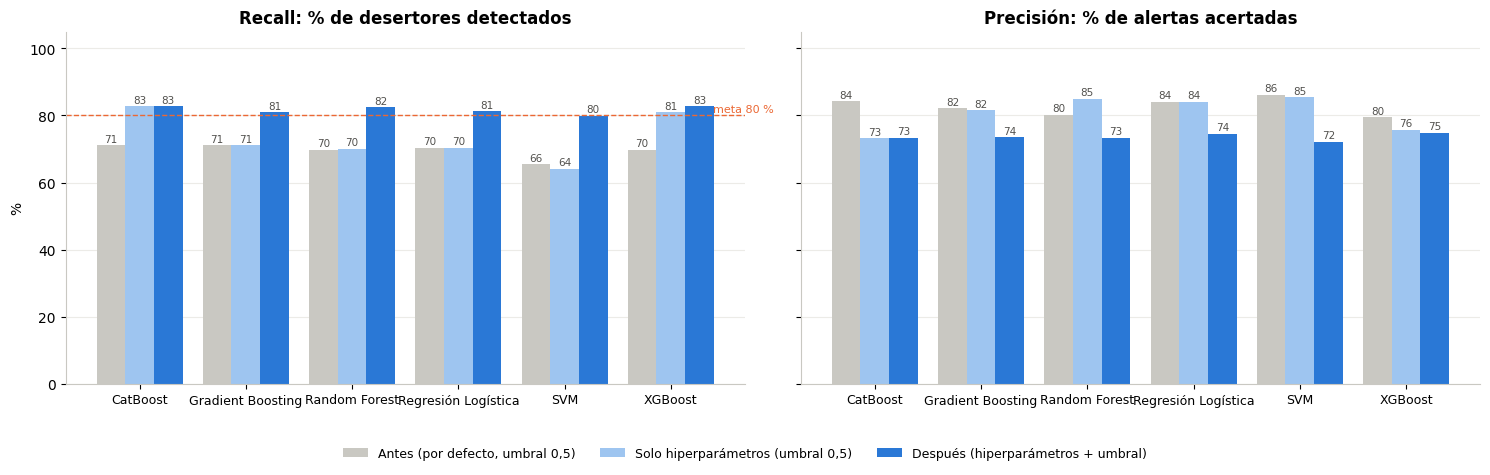

In [47]:
# Gráfico: Recall y Precisión de cada modelo en las tres versiones
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
versiones = [("antes", "#c9c8c2", "Antes (por defecto, umbral 0,5)"),
             ("solo hiperparámetros", "#9ec5f0", "Solo hiperparámetros (umbral 0,5)"),
             ("después", AZUL, "Después (hiperparámetros + umbral)")]
x = np.arange(len(comparacion))
for ax, metrica in zip(axes, ["Recall", "Precision"]):
    for k, (sufijo, color, etiqueta) in enumerate(versiones):
        valores = comparacion[f"{metrica} {sufijo}"] * 100
        ax.bar(x + (k - 1) * 0.27, valores, width=0.27, color=color, label=etiqueta)
        for xi, v in zip(x + (k - 1) * 0.27, valores):
            ax.text(xi, v + 1, f"{v:.0f}", ha="center", fontsize=7.5, color="#52514e")
    ax.set_xticks(x, comparacion.index, fontsize=9)
    ax.set_ylim(0, 105); ax.grid(axis="x", visible=False)
    ax.set_title("Recall: % de desertores detectados" if metrica == "Recall" else "Precisión: % de alertas acertadas")
axes[0].axhline(80, color=NARANJA, ls="--", lw=1); axes[0].text(len(x) - 0.6, 81, "meta 80 %", color=NARANJA, fontsize=8)
axes[0].set_ylabel("%")
fig.legend(*axes[1].get_legend_handles_labels(), frameon=False, fontsize=9, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

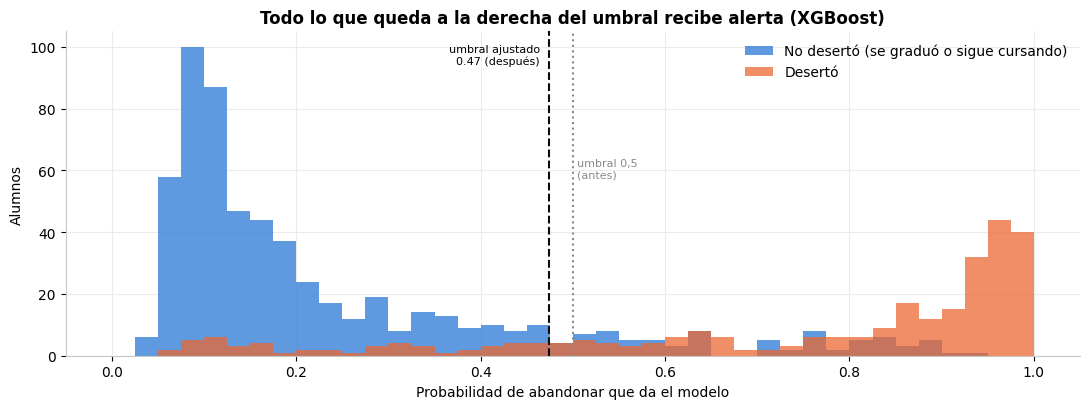

In [48]:
# Gráfico: cómo funciona la alerta. Riesgo que el modelo le asigna a cada alumno del test, según lo que realmente pasó
fig, ax = plt.subplots(figsize=(11, 4.2))
bins = np.linspace(0, 1, 41)
ax.hist(y_proba_final[y_test.values == 0], bins=bins, color=AZUL, alpha=0.75, label="No desertó (se graduó o sigue cursando)")
ax.hist(y_proba_final[y_test.values == 1], bins=bins, color=NARANJA, alpha=0.75, label="Desertó")
ax.axvline(0.5, color=GRIS, ls=":", lw=1.5)
ax.axvline(umbrales[modelo_elegido], color="#0b0b0b", ls="--", lw=1.5)
ax.text(0.505, ax.get_ylim()[1] * 0.55, "umbral 0,5\n(antes)", fontsize=8, color=GRIS)
ax.text(umbrales[modelo_elegido] - 0.01, ax.get_ylim()[1] * 0.9, f"umbral ajustado\n{umbrales[modelo_elegido]:.2f} (después)",
        fontsize=8, ha="right")
ax.set_xlabel("Probabilidad de abandonar que da el modelo"); ax.set_ylabel("Alumnos")
ax.set_title(f"Todo lo que queda a la derecha del umbral recibe alerta ({modelo_elegido})")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()
# Bajar el umbral de 0,5 a ~0,3 corre la línea a la izquierda: entran más desertores (naranja) pero también más no desertores (azul).

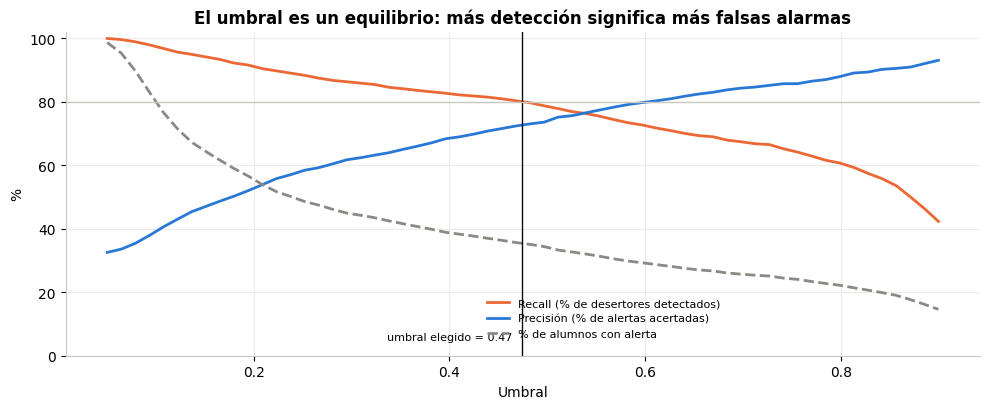

In [49]:
# Gráfico: qué pasa con cada umbral posible (validación cruzada del modelo elegido, sin usar el test)
prob_cv_final = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
umbrales_posibles = np.linspace(0.05, 0.9, 60)
curva_recall = [recall_score(y_train, prob_cv_final >= u) * 100 for u in umbrales_posibles]
curva_precision = [precision_score(y_train, prob_cv_final >= u, zero_division=0) * 100 for u in umbrales_posibles]
curva_marcados = [(prob_cv_final >= u).mean() * 100 for u in umbrales_posibles]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(umbrales_posibles, curva_recall, color=NARANJA, lw=2, label="Recall (% de desertores detectados)")
ax.plot(umbrales_posibles, curva_precision, color=AZUL, lw=2, label="Precisión (% de alertas acertadas)")
ax.plot(umbrales_posibles, curva_marcados, color=GRIS, lw=2, ls="--", label="% de alumnos con alerta")
ax.axvline(umbrales[modelo_elegido], color="#0b0b0b", lw=1)
ax.axhline(80, color="#c9c8c2", lw=1)
ax.text(umbrales[modelo_elegido] - 0.01, 5, f"umbral elegido = {umbrales[modelo_elegido]:.2f}", fontsize=8, ha="right")
ax.set_xlabel("Umbral"); ax.set_ylabel("%"); ax.set_ylim(0, 102)
ax.set_title("El umbral es un equilibrio: más detección significa más falsas alarmas")
ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0.45, 0.02))
plt.tight_layout()
plt.show()

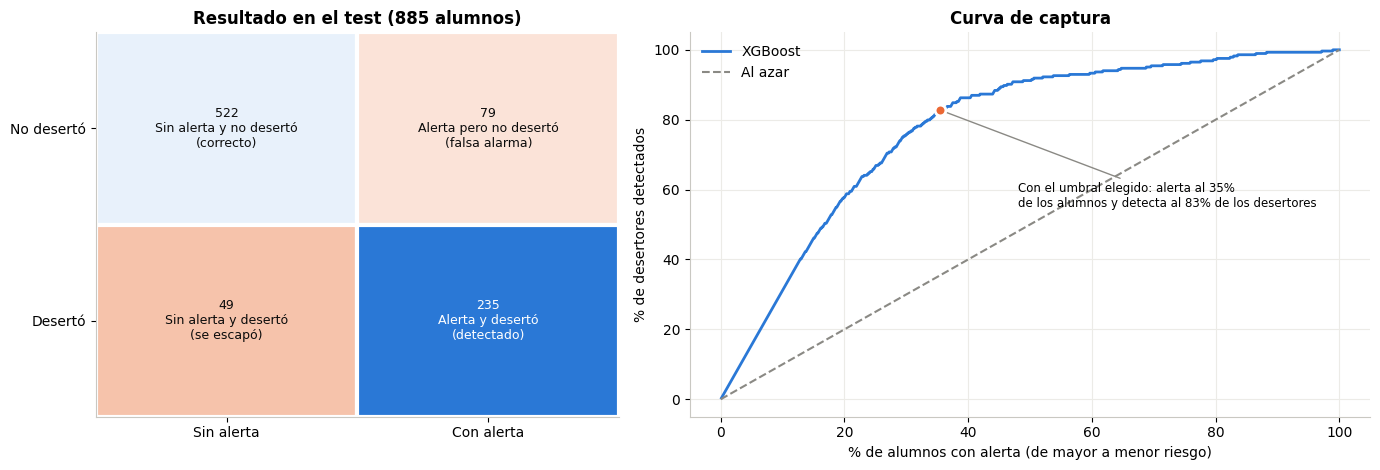

In [50]:
# Gráficos finales del modelo elegido: matriz de confusión y curva de captura
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})

ax = axes[0]
matriz = np.array([[vn, fp], [fn, vp]])
etiquetas = [["Sin alerta y no desertó\n(correcto)", "Alerta pero no desertó\n(falsa alarma)"],
             ["Sin alerta y desertó\n(se escapó)", "Alerta y desertó\n(detectado)"]]
colores_celda = [["#e8f1fb", "#fbe3d8"], ["#f6c3ab", "#2a78d6"]]
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=colores_celda[i][j], ec="white", lw=3))
        ax.text(j + 0.5, 1.5 - i, f"{matriz[i, j]}\n{etiquetas[i][j]}", ha="center", va="center", fontsize=9,
                color="white" if (i, j) == (1, 1) else "#0b0b0b")
ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_xticks([0.5, 1.5], ["Sin alerta", "Con alerta"])
ax.set_yticks([1.5, 0.5], ["No desertó", "Desertó"]); ax.grid(False)
ax.set_title(f"Resultado en el test ({len(y_test)} alumnos)")

ax = axes[1]
orden = np.argsort(-y_proba_final)
captura = np.cumsum(y_test.values[orden]) / y_test.sum() * 100
porc = np.arange(1, len(orden) + 1) / len(orden) * 100
ax.plot(porc, captura, color=AZUL, lw=2, label=f"{modelo_elegido}")
ax.plot([0, 100], [0, 100], color=GRIS, ls="--", lw=1.5, label="Al azar")
ax.scatter(y_pred_final.mean() * 100, recall_score(y_test, y_pred_final) * 100, s=60, color=NARANJA, zorder=5,
           edgecolor="white", linewidth=2)
ax.annotate(f"Con el umbral elegido: alerta al {y_pred_final.mean():.0%}\nde los alumnos y detecta al {recall_score(y_test, y_pred_final):.0%} de los desertores",
            (y_pred_final.mean() * 100, recall_score(y_test, y_pred_final) * 100), xytext=(48, 55), fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set_xlabel("% de alumnos con alerta (de mayor a menor riesgo)"); ax.set_ylabel("% de desertores detectados")
ax.set_title("Curva de captura"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

Ajuste de hiperparámetros y umbral, conclusiones:
- Los hiperparámetros solos casi no cambian el Recall (columna "solo hiperparámetros": XGBoost pasa de 69,7 % a 71,5 %). Mejoran apenas cómo el modelo ordena a los alumnos (PR-AUC en validación cruzada: 0,84 en los seis modelos).
- El cambio grande viene del umbral: bajarlo de 0,5 a ~0,3 hace que XGBoost pase de detectar el 70 % al 82 % de los desertores. El costo es que la Precisión baja de 80 % a 75 %: 1 de cada 4 alertas es una falsa alarma.
- La PR-AUC casi no cambia antes y después (de 0,85 a 0,88): el modelo no "aprendió mucho más", lo que cambió es dónde ponemos la vara para dar la alerta.
- Modelo elegido: XGBoost, el de mejor PR-AUC en validación cruzada. Es una suma de 400 árboles de decisión chicos (profundidad 3), donde cada árbol nuevo corrige los errores de los anteriores. Es un modelo de análisis temprano: solo usa lo que la institución ya sabe al cierre del 1er semestre (materias aprobadas y promedio del 1S, edad, carrera, vía de ingreso, beca, si paga la matrícula o tiene deudas, etc.) y da la alerta cuando el riesgo supera 0,32.
  - En el test, de 284 alumnos que abandonaron, detectó a 232 y se le escaparon 52, dando alerta al 35 % de los alumnos.
  - Los seis modelos quedan muy parejos, así que una Regresión Logística (más simple de explicar) sería una alternativa válida.
- Los gráficos muestran el equilibrio: casi todos los desertores tienen riesgo alto, pero hay un grupo de desertores con riesgo bajo (a la izquierda del umbral) que se parecen a los alumnos que no abandonan con los datos del 1er semestre. Son los que se escapan.

### Champion y Challenger
Idea tomada del trabajo de los compañeros: el modelo elegido (Champion) se compara en el test con una alternativa más simple de explicar (Challenger), ambos con su umbral ajustado.

In [51]:
# Champion y Challenger (idea del trabajo de los compañeros): el modelo elegido frente a la alternativa más simple
from sklearn.metrics import confusion_matrix
challenger = "Regresión Logística" if modelo_elegido != "Regresión Logística" else tabla_hiperparametros.index[1]

filas_cc = []
for rol, nombre in [("Champion", modelo_elegido), ("Challenger", challenger)]:
    prob = mejores[nombre].predict_proba(X_test)[:, 1]
    pred = prob >= umbrales[nombre]
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    filas_cc.append({"Rol": rol, "Modelo": nombre, "Umbral": umbrales[nombre],
                     "Recall": recall_score(y_test, pred), "Precisión": precision_score(y_test, pred),
                     "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, prob),
                     "PR-AUC": average_precision_score(y_test, prob),
                     "Detectados": vp, "No detectados": fn, "Falsas alarmas": fp})
pd.DataFrame(filas_cc).set_index("Rol").round(3)

,Modelo,Umbral,Recall,Precisión,F1,ROC-AUC,PR-AUC,Detectados,No detectados,Falsas alarmas
Rol,,,,,,,,,,
Champion,XGBoost,0.474,0.827,0.748,0.786,0.911,0.876,235,49,79
Challenger,Regresión Logística,0.305,0.813,0.745,0.778,0.903,0.867,231,53,79


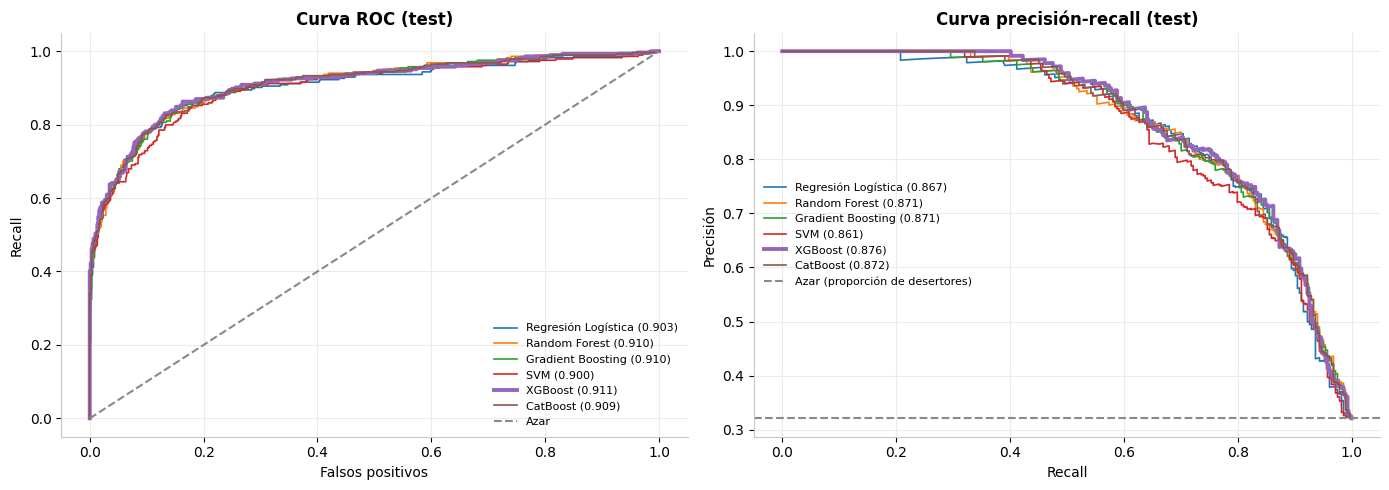

In [52]:
# Curvas ROC y precisión-recall de los modelos optimizados en el test (idea del trabajo de los compañeros)
from sklearn.metrics import roc_curve, precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, modelo in mejores.items():
    prob = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    grosor = 2.8 if nombre == modelo_elegido else 1.2
    axes[0].plot(fpr, tpr, lw=grosor, label=f"{nombre} ({roc_auc_score(y_test, prob):.3f})")
    axes[1].plot(rec, prec, lw=grosor, label=f"{nombre} ({average_precision_score(y_test, prob):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color=GRIS, label="Azar")
axes[1].axhline(y_test.mean(), ls="--", color=GRIS, label="Azar (proporción de desertores)")
axes[0].set(title="Curva ROC (test)", xlabel="Falsos positivos", ylabel="Recall")
axes[1].set(title="Curva precisión-recall (test)", xlabel="Recall", ylabel="Precisión")
for ax in axes:
    ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

- Los dos modelos detectan casi la misma cantidad de desertores con una precisión parecida, y las curvas de todos los modelos casi se superponen. La diferencia entre Champion y Challenger es de pocos alumnos, así que si se prioriza poder explicar el modelo, el Challenger es una opción válida sin perder casi nada.

### ¿Qué variables usa más el modelo elegido?
Mezclamos una variable a la vez en el test y vemos cuánto empeora el modelo. Cuanto más baja el PR-AUC, más depende de esa variable (idea de los trabajos de Gustavo y de los compañeros).

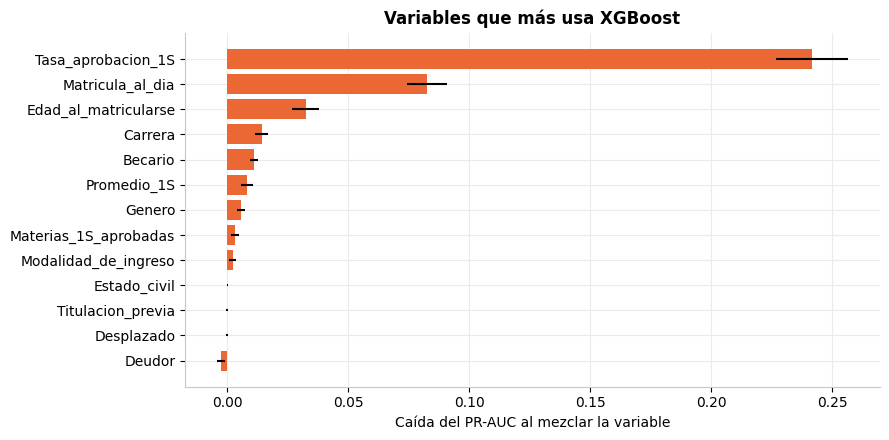

,Caída del PR-AUC,Desvío
Tasa_aprobacion_1S,0.2418,0.0149
Matricula_al_dia,0.0825,0.0082
Edad_al_matricularse,0.0325,0.0056
Carrera,0.0144,0.0027
Becario,0.0112,0.0018
Promedio_1S,0.0082,0.0024
Genero,0.0059,0.0017
Materias_1S_aprobadas,0.0034,0.0016
Modalidad_de_ingreso,0.0023,0.0016
Estado_civil,0.0001,0.0002


In [53]:
# ¿Qué variables usa más el modelo elegido? Mezclamos una variable a la vez en el test y medimos cuánto baja el PR-AUC
from sklearn.inspection import permutation_importance
imp = permutation_importance(modelo_final, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=42)
importancia = pd.DataFrame({"Caída del PR-AUC": imp.importances_mean, "Desvío": imp.importances_std},
                           index=X_test.columns).sort_values("Caída del PR-AUC", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
top = importancia.iloc[::-1]
ax.barh(top.index, top["Caída del PR-AUC"], xerr=top["Desvío"], color=NARANJA)
ax.set_xlabel("Caída del PR-AUC al mezclar la variable")
ax.set_title(f"Variables que más usa {modelo_elegido}")
plt.tight_layout()
plt.show()
importancia.round(4)

- El modelo se apoya sobre todo en el rendimiento del 1er semestre y en la situación de pago, lo mismo que mostraba el análisis inicial. Esto mide cuánto usa el modelo cada variable, no si la causa del abandono es esa.

### ¿Las diferencias entre modelos son reales?
Una tabla con un solo número por modelo no muestra si la diferencia es real o casualidad. Lo comprobamos remuestreando alumnos (idea del trabajo de Gustavo).

In [54]:
# ¿Las diferencias entre modelos son reales? (idea del trabajo de Gustavo)
# Comparamos el PR-AUC de cada modelo contra el elegido, remuestreando alumnos del entrenamiento 1000 veces (bootstrap)
prob_cv_modelos = {nombre: cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1] for nombre, m in mejores.items()}

y_arr = y_train.values
rng = np.random.default_rng(42)
muestras = [rng.integers(0, len(y_arr), len(y_arr)) for _ in range(1000)]

def pr_auc_bootstrap(p):
    return np.array([average_precision_score(y_arr[i], p[i]) for i in muestras])

base = pr_auc_bootstrap(prob_cv_modelos[modelo_elegido])
filas = []
for nombre, p in prob_cv_modelos.items():
    if nombre == modelo_elegido:
        continue
    dif = pr_auc_bootstrap(p) - base
    minimo, maximo = np.percentile(dif, [2.5, 97.5])
    filas.append({"Modelo": nombre, f"Diferencia de PR-AUC vs {modelo_elegido}": dif.mean(),
                  "Mínimo (IC 95 %)": minimo, "Máximo (IC 95 %)": maximo,
                  "¿Diferencia real?": "Sí" if minimo > 0 or maximo < 0 else "No"})
pd.DataFrame(filas).set_index("Modelo").round(3)


,Diferencia de PR-AUC vs XGBoost,Mínimo (IC 95 %),Máximo (IC 95 %),¿Diferencia real?
Modelo,,,,
Regresión Logística,-0.003,-0.010,0.003,No
Random Forest,-0.004,-0.010,0.001,No
Gradient Boosting,-0.004,-0.007,-0.000,Sí
SVM,-0.007,-0.014,-0.000,Sí
CatBoost,-0.002,-0.006,0.003,No


- Si el intervalo pasa por el 0, la diferencia con el modelo elegido es ruido. Gradient Boosting y SVM salen apenas peores (menos de 0,01 de PR-AUC) y el resto queda empatado. En la práctica los modelos rinden casi igual, así que una Regresión Logística, más simple de explicar, es una alternativa válida.

### Curva de ganancia
Si la institución tiene cupo limitado, puede contactar primero a los alumnos con más riesgo. La curva muestra a cuántos desertores llega según cuántos alumnos contacte (idea del trabajo de Gustavo).

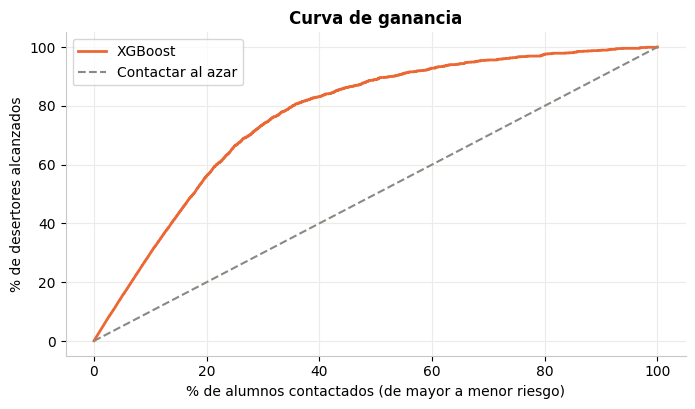

,% de desertores alcanzados,Veces mejor que al azar
% de alumnos contactados,,
10,29.7,2.97
20,56.0,2.80
30,73.6,2.45
40,83.1,2.08
50,88.9,1.78


In [55]:
# Curva de ganancia (idea del trabajo de Gustavo): si la institución contacta primero a los alumnos de mayor riesgo,
# ¿a qué % de los desertores llega según cuántos alumnos contacte? (validación cruzada, sin usar el test)
orden = np.argsort(-prob_cv_final)
alcanzados = np.cumsum(y_train.values[orden]) / y_train.sum() * 100
contactados = np.arange(1, len(orden) + 1) / len(orden) * 100

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(contactados, alcanzados, color=NARANJA, lw=2, label=modelo_elegido)
ax.plot([0, 100], [0, 100], ls="--", color=GRIS, label="Contactar al azar")
ax.set_xlabel("% de alumnos contactados (de mayor a menor riesgo)")
ax.set_ylabel("% de desertores alcanzados")
ax.set_title("Curva de ganancia")
ax.legend()
plt.show()

tabla_ganancia = pd.DataFrame({"% de alumnos contactados": [10, 20, 30, 40, 50]})
tabla_ganancia["% de desertores alcanzados"] = [round(alcanzados[int(len(orden) * k / 100) - 1], 1) for k in tabla_ganancia["% de alumnos contactados"]]
tabla_ganancia["Veces mejor que al azar"] = (tabla_ganancia["% de desertores alcanzados"] / tabla_ganancia["% de alumnos contactados"]).round(2)
tabla_ganancia.set_index("% de alumnos contactados")


- Contactando solo a una parte chica de los alumnos, los de más riesgo, ya se llega a la mayoría de los desertores, mucho más que eligiendo al azar. Si no alcanzan las tutorías para todos los alertados, conviene empezar por arriba de la lista.

### ¿Cuánto dependemos de las variables de pago?
Matrícula al día y Deudor pueden ser consecuencia del abandono y no la causa: el que ya decidió irse deja de pagar. Probamos el mismo modelo sin esas dos variables (idea del trabajo de Gustavo).

In [56]:
# ¿Cuánto dependemos de las variables de pago? (idea del trabajo de Gustavo)
# Matrícula al día y Deudor pueden ser consecuencia del abandono (el que se va deja de pagar), así que probamos el mismo modelo sin ellas
from sklearn.base import clone

sin_pago = [c for c in categoricas_en_X if c not in ["Matricula_al_dia", "Deudor"]]
filas = []
for version, categoricas_version in [("Con variables de pago", categoricas_en_X), ("Sin variables de pago", sin_pago)]:
    prep = ColumnTransformer([("num", StandardScaler(), numericas_en_X),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categoricas_version)])
    modelo = Pipeline([("prep", prep), ("modelo", clone(modelo_final.named_steps["modelo"]))])
    p = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    alerta = p >= umbral_para_recall(y_train, p, 0.80)
    filas.append({"Versión": version, "PR-AUC": average_precision_score(y_train, p),
                  "Precisión con Recall 80 %": precision_score(y_train, alerta),
                  "% de alumnos con alerta": alerta.mean() * 100})
pd.DataFrame(filas).set_index("Versión").round(3)


,PR-AUC,Precisión con Recall 80 %,% de alumnos con alerta
Versión,,,
Con variables de pago,0.842,0.728,35.321
Sin variables de pago,0.804,0.655,39.248


- Sin las variables de pago el modelo sigue funcionando, pero ordena peor y para detectar al 80 % necesita dar más alertas, con más falsas alarmas. O sea que el pago aporta información. Igual hay que tener cuidado: si el alumno deja de pagar porque ya decidió irse, esa alerta llega tarde. Conviene saber en qué momento del semestre la institución conoce ese dato.

### ¿A quién se parecen los Matriculados?
Si los matriculados fueran desertores o graduados "que todavía no sabemos", un modelo entrenado solo con desertores y graduados debería ubicarlos de un lado o del otro (idea del trabajo de Gustavo).

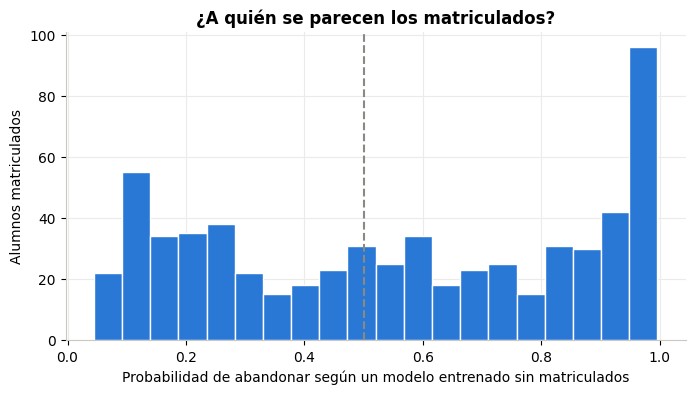

Matriculados que el modelo ve como desertores: 55.5 %
Probabilidad promedio: 0.56


In [57]:
# ¿Los Matriculados son desertores o graduados "que todavía no sabemos"? (idea del trabajo de Gustavo)
# Entrenamos el mismo modelo solo con desertores y graduados del entrenamiento, y le preguntamos qué piensa de los matriculados
resultado_train = desercion_escolar.loc[X_train.index, "Resultado"]
sin_matriculados = (resultado_train != "Matriculado").values
modelo_dg = clone(modelo_final).fit(X_train[sin_matriculados], y_train[sin_matriculados])
p_matriculados = modelo_dg.predict_proba(X_train[~sin_matriculados])[:, 1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(p_matriculados, bins=20, color=AZUL, edgecolor="white")
ax.axvline(0.5, ls="--", color=GRIS)
ax.set_xlabel("Probabilidad de abandonar según un modelo entrenado sin matriculados")
ax.set_ylabel("Alumnos matriculados")
ax.set_title("¿A quién se parecen los matriculados?")
plt.show()

print(f"Matriculados que el modelo ve como desertores: {(p_matriculados >= 0.5).mean() * 100:.1f} %")
print(f"Probabilidad promedio: {p_matriculados.mean():.2f}")


- El modelo no los puede ubicar: una buena parte queda del lado de los desertores y otra del lado de los graduados, con una probabilidad promedio cerca de la mitad. Los matriculados son un grupo propio, no un resultado pendiente. Por eso es correcto dejarlos en el entrenamiento como "no desertó", como pidió el profesor.

## 13. Recall vs. precisión: ¿cuántas falsas alarmas cuesta detectar más?
Cada meta de Recall implica un umbral distinto. La tabla muestra, para el modelo elegido y sobre los mismos 885 alumnos de prueba,
cuántos desertores se detectan y cuántos alumnos reciben alerta sin necesitarla (falsas alarmas).
El umbral de cada fila se elige con validación cruzada en el entrenamiento, igual que antes.

In [58]:
# Para cada meta de Recall: umbral elegido en validación cruzada (train) y resultado en el test
metas_recall = [0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
filas_rp = []
for meta in metas_recall:
    umbral_meta = umbral_para_recall(y_train, prob_cv_final, meta)
    alerta_meta = (y_proba_final >= umbral_meta).astype(int)
    detectados = int(((alerta_meta == 1) & (y_test.values == 1)).sum())
    falsas = int(((alerta_meta == 1) & (y_test.values == 0)).sum())
    filas_rp.append({"Meta de Recall": f"{meta:.0%}", "Umbral": round(umbral_meta, 3),
                     "Alumnos con alerta": int(alerta_meta.sum()), "Desertores detectados": detectados,
                     "Desertores no detectados": int(y_test.sum()) - detectados, "Falsas alarmas": falsas,
                     "Recall (test)": round(detectados / y_test.sum(), 3),
                     "Precisión (test)": round(detectados / alerta_meta.sum(), 3)})
tabla_rp = pd.DataFrame(filas_rp).set_index("Meta de Recall")
# Cuántas falsas alarmas nuevas aparecen por cada desertor nuevo que se detecta al pasar a la fila siguiente
tabla_rp["Falsas alarmas extra por desertor extra"] = (tabla_rp["Falsas alarmas"].diff() / tabla_rp["Desertores detectados"].diff()).round(1)
tabla_rp

,Umbral,Alumnos con alerta,Desertores detectados,Desertores no detectados,Falsas alarmas,Recall (test),Precisión (test),Falsas alarmas extra por desertor extra
Meta de Recall,,,,,,,,
60%,0.807,192,173,111,19,0.609,0.901,NaN
70%,0.641,245,202,82,43,0.711,0.824,0.8
75%,0.562,277,220,64,57,0.775,0.794,0.8
80%,0.474,314,235,49,79,0.827,0.748,1.5
85%,0.331,385,248,36,137,0.873,0.644,4.5
90%,0.215,465,262,22,203,0.923,0.563,4.7
95%,0.134,604,269,15,335,0.947,0.445,18.9


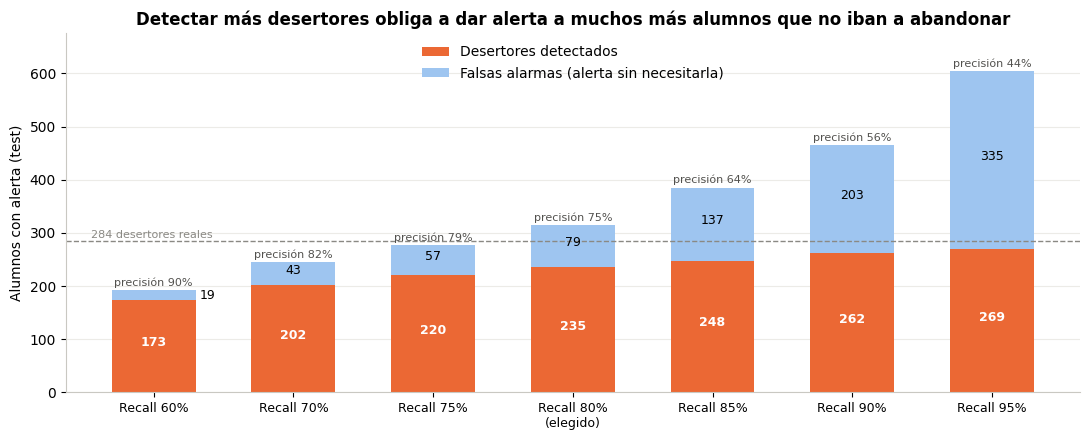

In [59]:
# Gráfico: alumnos con alerta = desertores detectados + falsas alarmas
fig, ax = plt.subplots(figsize=(11, 4.5))
posiciones = np.arange(len(tabla_rp))
ax.bar(posiciones, tabla_rp["Desertores detectados"], color=NARANJA, width=0.6, label="Desertores detectados")
ax.bar(posiciones, tabla_rp["Falsas alarmas"], bottom=tabla_rp["Desertores detectados"], color="#9ec5f0", width=0.6,
       label="Falsas alarmas (alerta sin necesitarla)")
for p, (det, fa, prec) in enumerate(zip(tabla_rp["Desertores detectados"], tabla_rp["Falsas alarmas"], tabla_rp["Precisión (test)"])):
    ax.text(p, det / 2, f"{det}", ha="center", color="white", fontsize=9, fontweight="bold")
    if fa >= 30:
        ax.text(p, det + fa / 2, f"{fa}", ha="center", fontsize=9)
    else:
        ax.text(p + 0.33, det + fa / 2, f"{fa}", va="center", fontsize=9)
    ax.text(p, det + fa + 8, f"precisión {prec:.0%}", ha="center", fontsize=8, color="#52514e")
ax.axhline(int(y_test.sum()), color=GRIS, ls="--", lw=1)
ax.text(-0.45, int(y_test.sum()) + 6, f"{int(y_test.sum())} desertores reales", fontsize=8, color=GRIS)
etiquetas_rp = [f"Recall {m}" + ("\n(elegido)" if m == "80%" else "") for m in tabla_rp.index]
ax.set_xticks(posiciones, etiquetas_rp, fontsize=9)
ax.set_ylabel("Alumnos con alerta (test)"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, (tabla_rp["Alumnos con alerta"].max()) * 1.12)
ax.set_title("Detectar más desertores obliga a dar alerta a muchos más alumnos que no iban a abandonar")
ax.legend(frameon=False, loc="upper center")
plt.tight_layout()
plt.show()

- Hasta el 80 % de Recall el costo es razonable: por cada desertor extra que se detecta aparecen 1 o 2 falsas alarmas.
- Pasar del 80 % al 90 % detecta 30 desertores más (232 → 262), pero suma 136 falsas alarmas (78 → 214): unas 4 o 5 por cada desertor extra, y la precisión baja de 75 % a 55 %.
- Por encima del 90 % casi no se gana nada: el modelo ya no distingue a los desertores que quedan de los alumnos que siguen.
- Por eso el 80 % es un buen punto de equilibrio. Si la institución tiene más capacidad de tutorías, 85 % todavía es razonable.

### Alarmas rojas, amarillas y falsas alarmas reales
Con el umbral elegido, no todos los alumnos con alerta que no abandonaron son errores del modelo. Muchos tienen malas notas o problemas de pago, igual que los desertores, y podrían abandonar más adelante.

Para separarlos usamos solo lo que se sabe al cierre del 1er semestre, sin nada del 2º:

| Tipo de alerta | Qué significa |
|---|---|
| Alarma roja | Recibió alerta y abandonó. El modelo acertó. |
| Alarma amarilla | Recibió alerta y no abandonó, pero aprobó la mitad o menos de sus materias del 1er semestre, o tiene la matrícula impaga o deudas. Está en riesgo. |
| Falsa alarma real | Recibió alerta, no abandonó y no tiene ninguna de esas señales. Es un error del modelo. |

In [60]:
# Señales de riesgo que ya se conocen al cierre del 1er semestre (no se usa nada del 2º semestre)
datos_test = desercion_escolar.loc[X_test.index]
no_desertor = (y_test == 0).values
con_notas = datos_test["Sin_datos_academicos"] == 0                            # los alumnos sin materias cargadas no cuentan para notas
malas_notas = (con_notas & (datos_test["Tasa_aprobacion_1S"] <= 0.5)).values   # aprobó la mitad o menos de sus materias
problema_pago = ((datos_test["Matricula_al_dia"] == "No") | (datos_test["Deudor"] == "Sí")).values
senal_riesgo = malas_notas | problema_pago

# Dice de qué tipo es cada alumno según si recibió alerta (True/False). Se define una vez y se usa en todo el apartado
def tipo_de_alerta(alerta):
    return pd.Series(np.select([~alerta, ~no_desertor, senal_riesgo],
                               ["Sin alerta", "Alarma roja", "Alarma amarilla"],
                               default="Falsa alarma real"), index=datos_test.index)

# Resumen con el umbral elegido
tipo = tipo_de_alerta(y_pred_final == 1)
orden_tipos = ["Alarma roja", "Alarma amarilla", "Falsa alarma real"]
conteo = tipo.value_counts().reindex(orden_tipos, fill_value=0)
print(f"El modelo dio alerta a {conteo.sum()} alumnos: {conteo['Alarma roja']} abandonaron, "
      f"{conteo['Alarma amarilla']} están en riesgo y {conteo['Falsa alarma real']} son falsas alarmas reales.")
resumen_alertas = pd.DataFrame({"Alumnos": conteo, "% de las alertas": (conteo / conteo.sum() * 100).round(1)})
resumen_alertas

El modelo dio alerta a 314 alumnos: 235 abandonaron, 44 están en riesgo y 35 son falsas alarmas reales.


,Alumnos,% de las alertas
Alarma roja,235,74.8
Alarma amarilla,44,14.0
Falsa alarma real,35,11.1


- Las alarmas rojas y amarillas son alumnos que necesitan algún tipo de ayuda, ya sea porque abandonaron o porque están en riesgo de hacerlo. Solo las falsas alarmas reales son alertas que se podrían haber evitado.

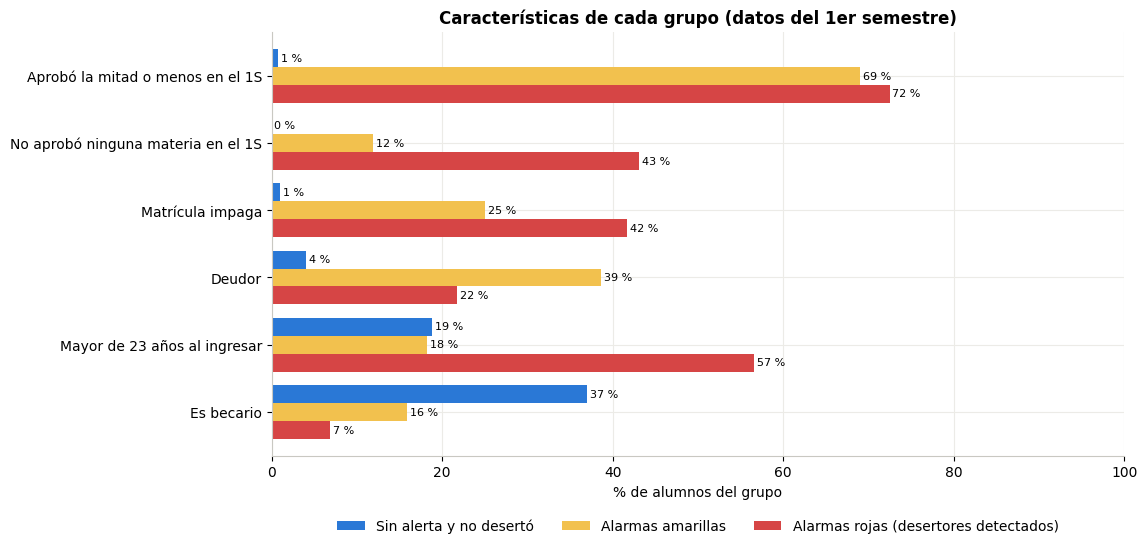

,Alarmas rojas (desertores detectados),Alarmas amarillas,Sin alerta y no desertó
Aprobó la mitad o menos en el 1S,72.5,69.0,0.8
No aprobó ninguna materia en el 1S,43.1,11.9,0.0
Matrícula impaga,41.7,25.0,1.0
Deudor,21.7,38.6,4.0
Mayor de 23 años al ingresar,56.6,18.2,18.8
Es becario,6.8,15.9,37.0


In [61]:
# ¿Cómo son las alarmas amarillas? Las comparamos con las rojas y con los alumnos sin alerta que no desertaron
grupos = {"Alarmas rojas (desertores detectados)": tipo == "Alarma roja",
          "Alarmas amarillas": tipo == "Alarma amarilla",
          "Sin alerta y no desertó": (tipo == "Sin alerta") & no_desertor}

def perfil(mascara):
    g = datos_test[mascara]
    gn = g[g["Sin_datos_academicos"] == 0]      # para las notas solo cuentan los alumnos con materias cargadas
    return {"Aprobó la mitad o menos en el 1S": (gn["Tasa_aprobacion_1S"] <= 0.5).mean() * 100,
            "No aprobó ninguna materia en el 1S": (gn["Tasa_aprobacion_1S"] == 0).mean() * 100,
            "Matrícula impaga": (g["Matricula_al_dia"] == "No").mean() * 100,
            "Deudor": (g["Deudor"] == "Sí").mean() * 100,
            "Mayor de 23 años al ingresar": (g["Edad_al_matricularse"] > 23).mean() * 100,
            "Es becario": (g["Becario"] == "Sí").mean() * 100}

tabla_perfil_amarillas = pd.DataFrame({nombre: perfil(m) for nombre, m in grupos.items()})
ax = tabla_perfil_amarillas.iloc[::-1].plot.barh(figsize=(11, 5.5), width=0.8, color=["#d64545", "#f2c14e", AZUL])
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f %%", padding=2, fontsize=8)
ax.set(xlim=(0, 100), xlabel="% de alumnos del grupo", ylabel="", title="Características de cada grupo (datos del 1er semestre)")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.show()

tabla_perfil_amarillas.round(1)

Las alarmas amarillas en el modelo elegido se parecen a los desertores en las notas y en los problemas de pago, y están muy lejos de los alumnos sin alerta. En la edad, en cambio, se parecen más a los que no abandonan. No abandonaron, pero si nadie los acompaña podrían terminar haciéndolo. Por eso conviene tratarlas como alumnos a seguir de cerca y no como errores del modelo.

### ¿Cómo separar a las amarillas de las falsas alarmas reales?
En la práctica no sabemos quién va a abandonar, así que la regla no puede usar el resultado, solo las señales del 1er semestre. Contamos cuántas tiene cada alumno con alerta: malas notas, matrícula impaga y deuda (de 0 a 3).

Regla simple:
- 1 señal o más: alumno a seguir de cerca (son las rojas con señales y las amarillas).
- 0 señales: falsa alarma probable, se excluye.

Después comprobamos con lo que realmente pasó cuánto acierta la regla.

In [62]:
# Cuántas señales de riesgo tiene cada alumno con alerta (0 a 3)
alerta = y_pred_final == 1
desertor = ~no_desertor
n_senales = (malas_notas.astype(int) + (datos_test["Matricula_al_dia"] == "No").values + (datos_test["Deudor"] == "Sí").values)

con_alerta = pd.DataFrame({"Señales de riesgo": n_senales[alerta], "Desertó": desertor[alerta]})
tabla_senales = con_alerta.groupby("Señales de riesgo")["Desertó"].agg(["size", "sum"]).reindex(range(4), fill_value=0)
tabla_senales.columns = ["Alumnos con alerta", "Desertaron"]
tabla_senales["No desertaron"] = tabla_senales["Alumnos con alerta"] - tabla_senales["Desertaron"]
tabla_senales["% que desertó"] = (tabla_senales["Desertaron"] / tabla_senales["Alumnos con alerta"] * 100).round(1)
tabla_senales

,Alumnos con alerta,Desertaron,No desertaron,% que desertó
Señales de riesgo,,,,
0,76,41,35,53.9
1,138,107,31,77.5
2,74,61,13,82.4
3,26,26,0,100.0


- A más señales, más alumnos abandonan, pero incluso entre los que no tienen ninguna más de la mitad abandonó. Las señales sirven para priorizar, pero no alcanzan para descartar a un alumno con alerta.

In [63]:
# Aplicamos la regla a todos los alumnos con alerta y la comparamos con lo que pasó
con_senal = n_senales >= 1
cuatro_grupos = {"Alarma roja con señales": alerta & desertor & con_senal,
                 "Alarma amarilla": alerta & no_desertor & con_senal,
                 "Alarma roja sin señales": alerta & desertor & ~con_senal,
                 "Falsa alarma real": alerta & no_desertor & ~con_senal}

tabla_regla = pd.DataFrame({"Alumnos": {nombre: int(m.sum()) for nombre, m in cuatro_grupos.items()}})
tabla_regla["% de las alertas"] = (tabla_regla["Alumnos"] / alerta.sum() * 100).round(1)
tabla_regla["Con la regla"] = ["Seguimiento", "Seguimiento", "Se excluye", "Se excluye"]
display(tabla_regla)

# Antes y después de excluir a los alumnos sin señales
total_desertores = int(desertor.sum())
def metricas(mascara):
    detectados = int((mascara & desertor).sum())
    return {"Alumnos a contactar": int(mascara.sum()),
            "Desertores cubiertos": detectados,
            "Desertores que se escapan": total_desertores - detectados,
            "Recall (%)": round(detectados / total_desertores * 100, 1),
            "Precisión (%)": round(detectados / mascara.sum() * 100, 1),
            "Falsas alarmas reales": int((mascara & no_desertor & ~con_senal).sum())}

comparacion_regla = pd.DataFrame({"Todas las alertas": pd.Series(metricas(alerta), dtype=object),
                                  "Solo alertas con señales": pd.Series(metricas(alerta & con_senal), dtype=object)})
print(f"Excluir a los alumnos sin señales saca {tabla_regla.loc['Falsa alarma real', 'Alumnos']} falsas alarmas reales, "
      f"pero también deja afuera a {tabla_regla.loc['Alarma roja sin señales', 'Alumnos']} desertores que el modelo sí había detectado.")
comparacion_regla

,Alumnos,% de las alertas,Con la regla
Alarma roja con señales,194,61.8,Seguimiento
Alarma amarilla,44,14.0,Seguimiento
Alarma roja sin señales,41,13.1,Se excluye
Falsa alarma real,35,11.1,Se excluye


Excluir a los alumnos sin señales saca 35 falsas alarmas reales, pero también deja afuera a 41 desertores que el modelo sí había detectado.


,Todas las alertas,Solo alertas con señales
Alumnos a contactar,314,238
Desertores cubiertos,235,194
Desertores que se escapan,49,90
Recall (%),82.7,68.3
Precisión (%),74.8,81.5
Falsas alarmas reales,35,0


- La regla saca todas las falsas alarmas reales, pero también deja afuera más desertores (alarmas rojas sin señales) de los que elimina en falsas alarmas. Se gana algo de Precisión y se pierde bastante Recall. Por eso conviene no excluir a nadie y usar las señales para dar prioridad: primero los que tienen más señales.

In [64]:
# ¿Y si cambiamos el umbral? Mismo conteo para cada meta de Recall de la sección anterior
conteos = {}
for meta in tabla_rp.index:
    umbral_meta = umbral_para_recall(y_train, prob_cv_final, int(meta[:-1]) / 100)
    conteos[meta] = tipo_de_alerta(y_proba_final >= umbral_meta).value_counts()

tabla_amarillas = pd.DataFrame(conteos).T.reindex(columns=orden_tipos).fillna(0).astype(int).rename_axis("Recall buscado")
tabla_amarillas["Alumnos con alerta"] = tabla_amarillas.sum(axis=1)
tabla_amarillas

,Alarma roja,Alarma amarilla,Falsa alarma real,Alumnos con alerta
Recall buscado,,,,
60%,173,16,3,192
70%,202,35,8,245
75%,220,39,18,277
80%,235,44,35,314
85%,248,54,83,385
90%,262,62,141,465
95%,269,68,267,604


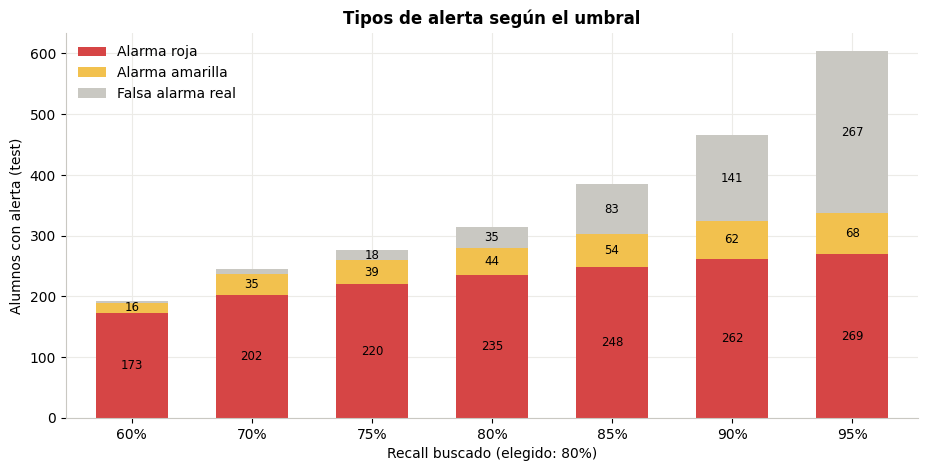

In [65]:
# Gráfico: cuántas alertas de cada tipo da el modelo según el umbral
ax = tabla_amarillas[orden_tipos].plot.bar(stacked=True, figsize=(11, 5), rot=0, width=0.6,
                                           color=["#d64545", "#f2c14e", "#c9c8c2"])
for barras in ax.containers:
    ax.bar_label(barras, label_type="center", fontsize=8.5,
                 labels=[f"{v:.0f}" if v >= 10 else "" for v in barras.datavalues])   # los números muy chicos no entran
ax.set(xlabel="Recall buscado (elegido: 80%)", ylabel="Alumnos con alerta (test)", title="Tipos de alerta según el umbral")
ax.legend(frameon=False, loc="upper left")
plt.show()

- Con metas de Recall bajas (umbral alto), casi todas las alertas que no son rojas son amarillas, es decir, alumnos con malas notas o problemas de pago. A medida que subimos la meta (umbral más bajo), las amarillas crecen poco y las falsas alarmas reales crecen mucho. En el punto elegido, una buena parte de las falsas alarmas son en realidad alumnos en riesgo.

## 14. Auditoría por subgrupos: ¿el modelo detecta igual a todos los grupos?

In [66]:
# Antes daba KeyError porque "Turno" no estaba en X_test (no pasó el umbral de V de Cramér).
# Ahora todas las columnas se toman del dataset completo con los índices del test.
datos_test = desercion_escolar.loc[X_test.index]
subgrupos_a_auditar = {
    "Necesidades educativas especiales": datos_test["Necesidades_educativas_especiales"] == "Sí",
    "Estudiante internacional": datos_test["Estudiante_internacional"] == "Sí",
    "Extranjero no lusófono": datos_test["Nacionalidad_agrupada"] == "Extranjero no lusófono",
    "Desplazado": datos_test["Desplazado"] == "Sí",
    "Turno nocturno": datos_test["Turno"] == "Nocturno",
    "Mayor de 23 años": datos_test["Modalidad_de_ingreso"] == "Mayor de 23 años",
    "Becario": datos_test["Becario"] == "Sí",
    "Becario y Deudor a la vez": (datos_test["Becario"] == "Sí") & (datos_test["Deudor"] == "Sí"),
    "Mujeres": datos_test["Genero"] == "Femenino",
    "Hombres": datos_test["Genero"] == "Masculino",
    "Hombres en carreras feminizadas": (datos_test["Genero"] == "Masculino") & (datos_test["Carrera"].isin(["Enfermería", "Higiene Bucal"])),
    "Matriculados (no desertan)": datos_test["Resultado"] == "Matriculado",
}

# AGREGADO: para cada subgrupo, cuántos desertores tiene y qué % detecta el modelo final
filas = []
for nombre, mascara in subgrupos_a_auditar.items():
    mascara = mascara.values
    y_grupo = y_test.values[mascara]
    filas.append({
        "Subgrupo": nombre,
        "Alumnos": mascara.sum(),
        "% desertores": round(y_grupo.mean() * 100, 1) if mascara.sum() else np.nan,
        "% marcados por el modelo": round(y_pred_final[mascara].mean() * 100, 1) if mascara.sum() else np.nan,
        "Recall del grupo": round(recall_score(y_grupo, y_pred_final[mascara]) * 100, 1) if y_grupo.sum() else np.nan,
    })
auditoria = pd.DataFrame(filas).set_index("Subgrupo")
print("Grupos con menos de 30 alumnos: sus porcentajes no son confiables.")
auditoria

Grupos con menos de 30 alumnos: sus porcentajes no son confiables.


,Alumnos,% desertores,% marcados por el modelo,Recall del grupo
Subgrupo,,,,
Necesidades educativas especiales,10,20.0,10.0,50.0
Estudiante internacional,26,30.8,50.0,100.0
Extranjero no lusófono,8,25.0,37.5,100.0
Desplazado,500,28.4,30.0,78.9
Turno nocturno,97,44.3,49.5,88.4
Mayor de 23 años,165,55.8,61.8,93.5
Becario,231,12.6,10.8,55.2
Becario y Deudor a la vez,22,31.8,50.0,100.0
Mujeres,564,24.5,26.8,80.4


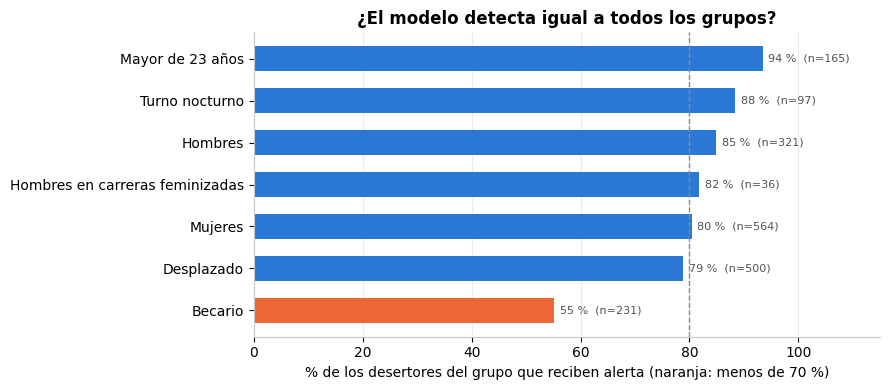

In [67]:
# Gráfico: Recall por subgrupo (solo grupos con al menos 30 alumnos y algún desertor)
graf = auditoria[(auditoria["Alumnos"] >= 30) & auditoria["Recall del grupo"].notna()].sort_values("Recall del grupo")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(graf.index, graf["Recall del grupo"], color=[NARANJA if v < 70 else AZUL for v in graf["Recall del grupo"]], height=0.6)
for i, (v, n) in enumerate(zip(graf["Recall del grupo"], graf["Alumnos"])):
    ax.text(v + 1, i, f"{v:.0f} %  (n={n})", va="center", fontsize=8, color="#52514e")
ax.axvline(80, color=GRIS, ls="--", lw=1)
ax.set_xlim(0, 115); ax.set_xlabel("% de los desertores del grupo que reciben alerta (naranja: menos de 70 %)")
ax.set_title("¿El modelo detecta igual a todos los grupos?"); ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- El modelo detecta muy bien a los grupos de mayor riesgo: al 95 % de los desertores mayores de 23 años y al 91 % de los del turno nocturno. El punto débil son los becarios: solo detecta al 55 % de los que abandonan, porque la beca suele venir con buen rendimiento y la cuota pagada, y el modelo no ve señales de alarma. Los grupos de menos de 30 alumnos no permiten sacar conclusiones.

### Brechas de detección entre grupos
Idea tomada del trabajo de los compañeros: comparamos qué parte de los desertores detecta el modelo elegido en cada grupo, y la diferencia entre grupos de una misma dimensión.

In [68]:
# Brechas de detección del modelo elegido entre grupos (idea del trabajo de los compañeros)
datos_brechas = desercion_escolar.loc[X_test.index]
es_desertor = y_test.values == 1
tiene_alerta = y_pred_final == 1
dimensiones = {
    "Género": datos_brechas["Genero"].values,
    "Deuda": np.where(datos_brechas["Deudor"] == "Sí", "Con deuda", "Sin deuda"),
    "Matrícula": np.where(datos_brechas["Matricula_al_dia"] == "Sí", "Al día", "No al día"),
    "Titulación previa": np.where(datos_brechas["Titulacion_previa"] == "Educación secundaria", "Secundaria", "Otras formaciones"),
}
filas_br = []
for dimension, grupo in dimensiones.items():
    for valor in sorted(set(grupo)):
        en_grupo = grupo == valor
        filas_br.append({"Dimensión": dimension, "Grupo": valor, "Alumnos": en_grupo.sum(),
                         "Desertores": (en_grupo & es_desertor).sum(),
                         "Detectados": (en_grupo & es_desertor & tiene_alerta).sum(),
                         "No detectados": (en_grupo & es_desertor & ~tiene_alerta).sum()})
tabla_brechas = pd.DataFrame(filas_br).set_index(["Dimensión", "Grupo"])
tabla_brechas["Recall (%)"] = (tabla_brechas["Detectados"] / tabla_brechas["Desertores"] * 100).round(1)
display(tabla_brechas)

resumen_brechas = tabla_brechas.groupby(level=0)["Recall (%)"].agg(lambda r: r.max() - r.min()).round(1)
resumen_brechas.sort_values(ascending=False).to_frame("Brecha de Recall (puntos)")

Alumnos  Desertores  Detectados  \
Dimensión         Grupo                                                
Género            Femenino               564         138         111   
                  Masculino              321         146         124   
Deuda             Con deuda               90          52          51   
                  Sin deuda              795         232         184   
Matrícula         Al día                 771         186         137   
                  No al día              114          98          98   
Titulación previa Otras formaciones      152          82          75   
                  Secundaria             733         202         160   

                                     No detectados  Recall (%)  
Dimensión         Grupo                                         
Género            Femenino                      27        80.4  
                  Masculino                     22        84.9  
Deuda             Con deuda                      1        98.1  
                  Sin deuda                     48        79.3  
Matrícula         Al día                        49        73.7  
                  No al día                      0       100.0  
Titulación previa Otras formaciones              7        91.5  
                  Secundaria                    42        79.2

,Brecha de Recall (puntos)
Dimensión,
Matrícula,26.3
Deuda,18.8
Titulación previa,12.3
Género,4.5


- La diferencia más grande aparece según la situación de pago: el modelo detecta a casi todos los que deben o tienen la matrícula impaga, y bastante menos a los que están al día. Los desertores que se escapan son justamente los que no muestran problemas de pago, igual que en la sección 15. En género y titulación previa las diferencias son menores.

## 15. ¿Quiénes se escapan? Desertores no detectados
Comparamos a los desertores que el modelo no detectó con los que sí detectó y con los alumnos que no abandonaron.

Grupo
Desertor detectado       235
Desertor NO detectado     49
No desertó               601
Name: count, dtype: int64


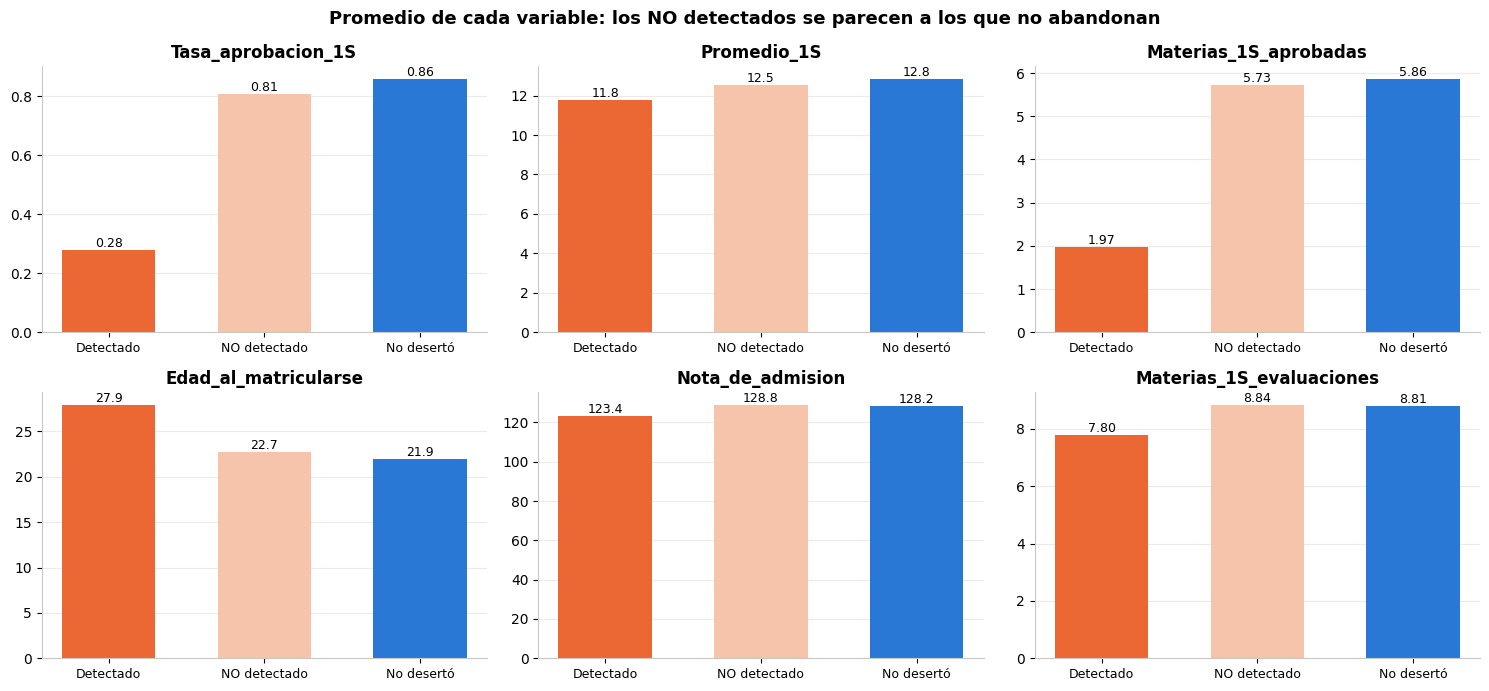

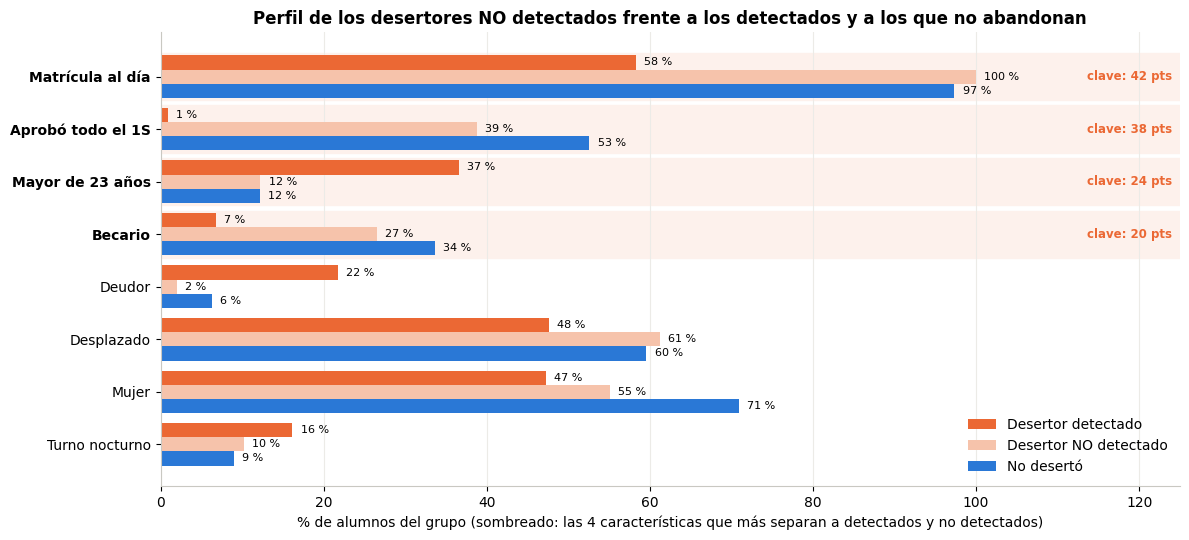

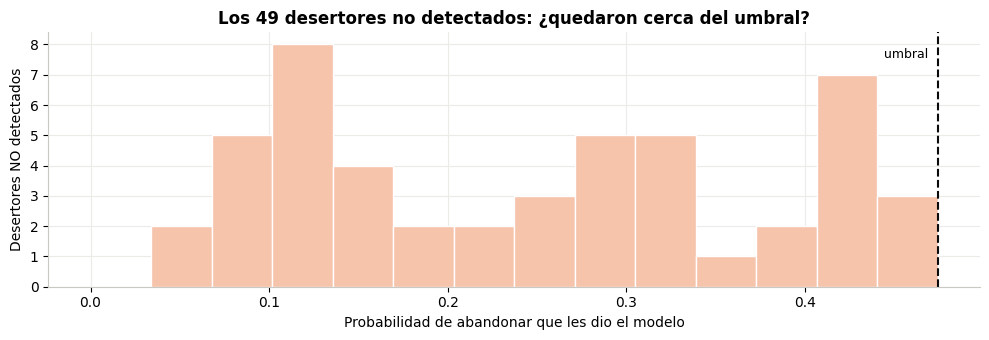

In [69]:
# ¿Cómo son los desertores que el modelo NO detectó? Comparación con los detectados y con los que no abandonaron (test)
datos_test = desercion_escolar.loc[X_test.index].copy()
real, alerta = y_test.values, y_pred_final
datos_test["Grupo"] = np.select(
    [(real == 1) & (alerta == 1), (real == 1) & (alerta == 0), real == 0],
    ["Desertor detectado", "Desertor NO detectado", "No desertó"], default="")
orden_grupos = ["Desertor detectado", "Desertor NO detectado", "No desertó"]
colores_grupos = {"Desertor detectado": NARANJA, "Desertor NO detectado": "#f6c3ab", "No desertó": AZUL}
print(datos_test["Grupo"].value_counts().reindex(orden_grupos))

# 1) Variables numéricas: promedio de cada grupo
variables_num = ["Tasa_aprobacion_1S", "Promedio_1S", "Materias_1S_aprobadas", "Edad_al_matricularse",
                 "Nota_de_admision", "Materias_1S_evaluaciones"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), variables_num):
    valores = datos_test[col].replace(0, np.nan) if col == "Promedio_1S" else datos_test[col]
    promedios = valores.groupby(datos_test["Grupo"]).mean().reindex(orden_grupos)
    ax.bar(range(3), promedios, color=[colores_grupos[g] for g in orden_grupos], width=0.6)
    for i, v in enumerate(promedios):
        ax.text(i, v, f"{v:.2f}" if v < 10 else f"{v:.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(3), ["Detectado", "NO detectado", "No desertó"], fontsize=9)
    ax.set_title(col); ax.grid(axis="x", visible=False)
fig.suptitle("Promedio de cada variable: los NO detectados se parecen a los que no abandonan", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

# 2) Variables categóricas: % de cada grupo que tiene la característica
caracteristicas = {
    "Becario": datos_test["Becario"] == "Sí",
    "Matrícula al día": datos_test["Matricula_al_dia"] == "Sí",
    "Deudor": datos_test["Deudor"] == "Sí",
    "Mujer": datos_test["Genero"] == "Femenino",
    "Mayor de 23 años": datos_test["Modalidad_de_ingreso"] == "Mayor de 23 años",
    "Turno nocturno": datos_test["Turno"] == "Nocturno",
    "Desplazado": datos_test["Desplazado"] == "Sí",
    "Aprobó todo el 1S": datos_test["Tasa_aprobacion_1S"] >= 1,
}
tabla_car = pd.DataFrame({n: m.groupby(datos_test["Grupo"]).mean() * 100 for n, m in caracteristicas.items()}).reindex(orden_grupos).T
# Diferencia entre desertores detectados y no detectados: las más grandes explican por qué se escapan
tabla_car["Diferencia"] = (tabla_car["Desertor NO detectado"] - tabla_car["Desertor detectado"]).abs()
tabla_car = tabla_car.sort_values("Diferencia", ascending=False)
claves = tabla_car.index[:4]

fig, ax = plt.subplots(figsize=(12, 5.5))
posiciones = np.arange(len(tabla_car))
for p in posiciones[:len(claves)]:
    ax.axhspan(p - 0.45, p + 0.45, color="#fdf1ec", zorder=0)
for k, g in enumerate(orden_grupos):
    ax.barh(posiciones + (k - 1) * 0.27, tabla_car[g], height=0.27, color=colores_grupos[g], label=g)
    for yi, v in zip(posiciones + (k - 1) * 0.27, tabla_car[g]):
        ax.text(v + 1, yi, f"{v:.0f} %", va="center", fontsize=8)
for p, nombre in zip(posiciones[:len(claves)], claves):
    ax.text(124, p, f"clave: {tabla_car.loc[nombre, 'Diferencia']:.0f} pts", va="center", ha="right", fontsize=8.5,
            color=NARANJA, fontweight="bold")
ax.set_yticks(posiciones, tabla_car.index); ax.invert_yaxis(); ax.set_xlim(0, 125)
for etiqueta in ax.get_yticklabels():
    if etiqueta.get_text() in claves:
        etiqueta.set_fontweight("bold")
ax.set_xlabel("% de alumnos del grupo (sombreado: las 4 características que más separan a detectados y no detectados)")
ax.grid(axis="y", visible=False)
ax.set_title("Perfil de los desertores NO detectados frente a los detectados y a los que no abandonan")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

# 3) Probabilidad que el modelo les dio: ¿quedaron cerca del umbral o muy lejos?
fig, ax = plt.subplots(figsize=(10, 3.5))
prob_no_detectados = y_proba_final[(real == 1) & (alerta == 0)]
ax.hist(prob_no_detectados, bins=np.linspace(0, umbrales[modelo_elegido], 15), color="#f6c3ab", edgecolor="white")
ax.axvline(umbrales[modelo_elegido], color="#0b0b0b", ls="--")
ax.text(umbrales[modelo_elegido] - 0.005, ax.get_ylim()[1] * 0.9, "umbral", ha="right", fontsize=9)
ax.set_xlabel("Probabilidad de abandonar que les dio el modelo"); ax.set_ylabel("Desertores NO detectados")
ax.set_title(f"Los {len(prob_no_detectados)} desertores no detectados: ¿quedaron cerca del umbral?")
plt.tight_layout()
plt.show()

- Los 52 desertores que se escapan se parecen mucho más a los alumnos que terminan que a los otros desertores: aprueban el 76 % de sus materias, tienen promedio 12,6 y 22 años de edad promedio.
- Las 4 características clave (sombreadas) lo explican: casi todos tienen la matrícula al día (98 %) y ninguno es deudor, el 37 % aprobó todo el 1er semestre y casi ninguno es mayor de 23 años. Además, 1 de cada 4 es becario.
- Abandonan sin mostrar problemas académicos ni económicos. Probablemente se van por motivos que el dataset no registra: vocación, cambio de carrera, trabajo, familia o expectativas no cumplidas.
- La mayoría recibió un riesgo bajo, lejos del umbral: bajar un poco el umbral no los recupera.

### Desertores no detectados por carrera
Vemos en qué carreras estaban los desertores que se escapan.

In [70]:
# Desertores NO detectados por carrera (test): ¿hay carreras donde se escapan más?
desertores = datos_test[datos_test["Grupo"] != "No desertó"]
por_carrera = desertores.groupby("Carrera")["Grupo"].value_counts().unstack(fill_value=0)
por_carrera["Desertores"] = por_carrera.sum(axis=1)
por_carrera["% no detectados"] = (por_carrera["Desertor NO detectado"] / por_carrera["Desertores"] * 100).round(1)
por_carrera["% deserción de la carrera"] = tabla_carreras["Porcentaje_desercion"]
por_carrera[["Desertores", "Desertor NO detectado", "% no detectados", "% deserción de la carrera"]].sort_values("Desertor NO detectado", ascending=False)


Grupo,Desertores,Desertor NO detectado,% no detectados,% deserción de la carrera
Carrera,,,,
Enfermería,28,8,28.6,15.4
Publicidad y Gestión de Marketing,20,6,30.0,35.4
Gestión,49,6,12.2,41.7
Diseño de Animación y Multimedia,24,5,20.8,38.1
Servicio Social,27,4,14.8,23.9
Educación Básica,19,4,21.1,44.3
Ingeniería Informática,19,3,15.8,54.1
Periodismo y Comunicación,24,3,12.5,30.5
Enfermería Veterinaria,11,2,18.2,26.7


- Los desertores que se escapan están repartidos en casi todas las carreras, no se concentran en una sola. Enfermería es la que más tiene, y es justo una de las carreras con menos deserción. En general se escapan un poco más en las carreras donde abandonar es menos común, porque ahí el modelo ve menos casos parecidos para aprender. Son pocos alumnos por carrera, así que sirve como pista y no como regla.

Desertores atipicos

In [71]:
# Perfil atípico: desertores con beca y buenas notas (aprobaron más del 80 % de las materias del 1er semestre)
desertores = datos_test[datos_test["Grupo"] != "No desertó"]
atipicos = desertores[(desertores["Becario"] == "Sí") & (desertores["Tasa_aprobacion_1S"] > 0.8)]

tabla_atipicos = atipicos.groupby("Carrera")["Grupo"].value_counts().unstack(fill_value=0)
tabla_atipicos["Total"] = tabla_atipicos.sum(axis=1)
tabla_atipicos = tabla_atipicos.sort_values("Total", ascending=False)
tabla_atipicos.loc["Total"] = tabla_atipicos.sum()
tabla_atipicos

Grupo,Desertor NO detectado,Desertor detectado,Total
Carrera,,,
Periodismo y Comunicación,2,1,3
Enfermería,2,0,2
Servicio Social,2,0,2
Ingeniería Informática,1,0,1
Higiene Bucal,1,0,1
Total,8,1,9


Los desertores que el modelo no ve no dependen de una carrera en particular. El perfil con beca y buenas notas es la parte más clara de ese grupo, pero es pequeña (8 de los 52). El resto de los no detectados tampoco muestra señales de riesgo, así que en ambos casos el motivo del abandono parece estar fuera de lo que registra el dataset. Se recomienda ampliar los datos para determinar el abandono de alumnos con buen perfil académico si se quiere mejorar el modelo. Aunque se basaría en una minoría, el modelo cumple con las detecciones de riesgo mayoritarias.

## 16. ¿Cuánto le cuesta a la institución? Horas de tutoría
El dataset no trae datos económicos (costos, sueldos, aranceles) y abarca unos 10 años de cohortes, así que no se puede calcular la inversión en dinero.
En su lugar la medimos en horas docentes: cuántas horas de tutoría por mes hacen falta para acompañar a los alumnos con alerta,
comparadas con las horas netas de clase normal que ya da la institución. El resultado es el % de inversión extra.

- Clase normal: 1 hora docente atiende a toda una comisión (por ejemplo, 30 alumnos).
- Tutoría: 1 hora docente atiende a 1 alumno (individual) o a un grupo chico (por ejemplo, 5).

Los valores de abajo son supuestos editables: cambiándolos se recalcula todo.

In [72]:
# Supuestos (editables)
HORAS_CLASE_SEMANA = 20     # horas de clase por semana de un alumno de tiempo completo
ALUMNOS_POR_COMISION = 30   # alumnos que atiende 1 hora de clase normal
HORAS_TUTORIA_SEMANA = 1    # horas de tutoría por semana para cada alumno con alerta
SEMANAS_POR_MES = 4
EFECTIVIDAD = 0.25          # % de los desertores acompañados que finalmente NO abandona

alumnos = len(y_test)
horas_clase_mes = alumnos / ALUMNOS_POR_COMISION * HORAS_CLASE_SEMANA * SEMANAS_POR_MES
print(f"Horas docentes de clase normal por mes para {alumnos} alumnos: {horas_clase_mes:.0f}")

filas_costo = []
for meta, fila in tabla_rp.iterrows():
    for modalidad, por_grupo in [("Individual", 1), ("Grupos de 5", 5)]:
        horas_tutoria = fila["Alumnos con alerta"] / por_grupo * HORAS_TUTORIA_SEMANA * SEMANAS_POR_MES
        horas_falsas = fila["Falsas alarmas"] / por_grupo * HORAS_TUTORIA_SEMANA * SEMANAS_POR_MES
        retenidos = fila["Desertores detectados"] * EFECTIVIDAD
        filas_costo.append({"Meta de Recall": meta, "Modalidad": modalidad,
                            "Horas de tutoría por mes": round(horas_tutoria),
                            "% de inversión extra (vs. horas de clase)": round(horas_tutoria / horas_clase_mes * 100, 1),
                            "Horas en falsas alarmas": round(horas_falsas),
                            "Alumnos retenidos (estimado)": round(retenidos, 1),
                            "Horas de tutoría por mes por alumno retenido": round(horas_tutoria / retenidos, 1)})
tabla_costo = pd.DataFrame(filas_costo).set_index(["Meta de Recall", "Modalidad"])
tabla_costo

Horas docentes de clase normal por mes para 885 alumnos: 2360


Horas de tutoría por mes  \
Meta de Recall Modalidad                               
60%            Individual                        768   
               Grupos de 5                       154   
70%            Individual                        980   
               Grupos de 5                       196   
75%            Individual                       1108   
               Grupos de 5                       222   
80%            Individual                       1256   
               Grupos de 5                       251   
85%            Individual                       1540   
               Grupos de 5                       308   
90%            Individual                       1860   
               Grupos de 5                       372   
95%            Individual                       2416   
               Grupos de 5                       483   

                            % de inversión extra (vs. horas de clase)  \
Meta de Recall Modalidad                                                
60%            Individual                                        32.5   
               Grupos de 5                                        6.5   
70%            Individual                                        41.5   
               Grupos de 5                                        8.3   
75%            Individual                                        46.9   
               Grupos de 5                                        9.4   
80%            Individual                                        53.2   
               Grupos de 5                                       10.6   
85%            Individual                                        65.3   
               Grupos de 5                                       13.1   
90%            Individual                                        78.8   
               Grupos de 5                                       15.8   
95%            Individual                                       102.4   
               Grupos de 5                                       20.5   

                            Horas en falsas alarmas  \
Meta de Recall Modalidad                              
60%            Individual                        76   
               Grupos de 5                       15   
70%            Individual                       172   
               Grupos de 5                       34   
75%            Individual                       228   
               Grupos de 5                       46   
80%            Individual                       316   
               Grupos de 5                       63   
85%            Individual                       548   
               Grupos de 5                      110   
90%            Individual                       812   
               Grupos de 5                      162   
95%            Individual                      1340   
               Grupos de 5                      268   

                            Alumnos retenidos (estimado)  \
Meta de Recall Modalidad                                   
60%            Individual                           43.2   
               Grupos de 5                          43.2   
70%            Individual                           50.5   
               Grupos de 5                          50.5   
75%            Individual                           55.0   
               Grupos de 5                          55.0   
80%            Individual                           58.8   
               Grupos de 5                          58.8   
85%            Individual                           62.0   
               Grupos de 5                          62.0   
90%            Individual                           65.5   
               Grupos de 5                          65.5   
95%            Individual                           67.2   
               Grupos de 5                          67.2   

                            Horas de tutoría por mes por alumno retenido  
Meta de Recall Modalidad                     

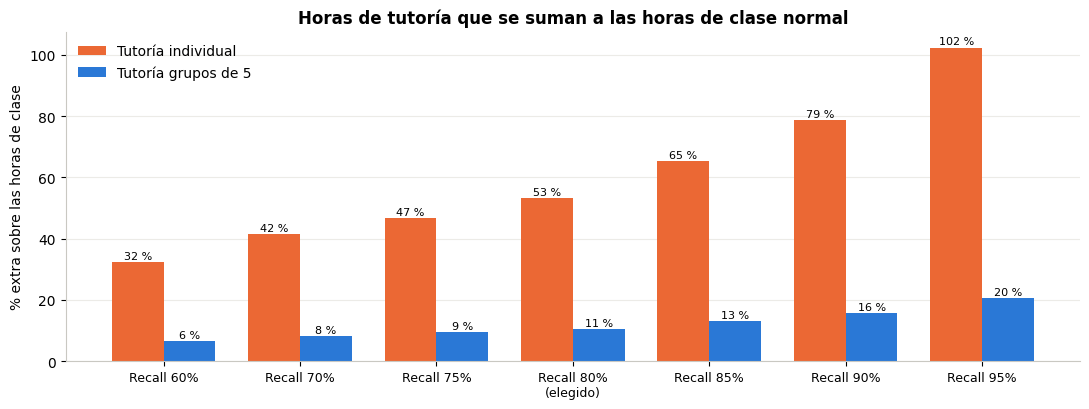

In [73]:
# Gráfico: % de inversión extra en horas docentes según la meta de Recall
fig, ax = plt.subplots(figsize=(11, 4.2))
posiciones = np.arange(len(tabla_rp))
for k, (modalidad, color) in enumerate([("Individual", NARANJA), ("Grupos de 5", AZUL)]):
    valores = tabla_costo.xs(modalidad, level="Modalidad")["% de inversión extra (vs. horas de clase)"]
    ax.bar(posiciones + (k - 0.5) * 0.38, valores, width=0.38, color=color, label=f"Tutoría {modalidad.lower()}")
    for p, v in zip(posiciones + (k - 0.5) * 0.38, valores):
        ax.text(p, v + 1, f"{v:.0f} %", ha="center", fontsize=8)
ax.set_xticks(posiciones, [f"Recall {m}" + ("\n(elegido)" if m == "80%" else "") for m in tabla_rp.index], fontsize=9)
ax.set_ylabel("% extra sobre las horas de clase"); ax.grid(axis="x", visible=False)
ax.set_title("Horas de tutoría que se suman a las horas de clase normal")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

- Con la meta elegida (Recall 80 %), la tutoría individual de 1 hora semanal suma 1.240 horas docentes por mes, un 52,5 % más que las horas de clase normal. En grupos de 5 baja a 248 horas: un 10,5 % extra.
- 312 de esas horas individuales (25 %) se van en falsas alarmas. No son del todo perdidas: muchos de esos alumnos están atrasados (matriculados) y el acompañamiento también les sirve.
- Con una efectividad del 25 %, cada alumno retenido requiere unas 21 horas de tutoría por mes (individual) o 4,3 (grupal).
- Subir la meta al 90 % encarece mucho: la inversión extra pasa de 52,5 % a 81 % en tutoría individual.

Otras ideas para medir la inversión sin datos económicos:
- Horas por alumno retenido: horas de tutoría ÷ alumnos retenidos. Permite comparar programas (tutoría individual, grupal, mentoría entre alumnos avanzados) sin conocer sueldos.
- Vacantes recuperadas: cuando un alumno abandona, su lugar queda vacío los años que le faltaban, pero la clase se dicta igual. Retenerlo aprovecha horas que la institución ya paga. Con el dato de la matrícula anual o del aporte del Estado por alumno, multiplicándolo por los alumnos retenidos y los años que les faltan se obtiene el beneficio en dinero.
- Tutoría escalonada: individual solo para el riesgo más alto y grupal para el resto. Baja las horas sin dejar de acompañar a nadie.

## 17. Posibles soluciones
A partir del análisis, estas son acciones concretas que la institución podría tomar:

| Hallazgo | Posible solución |
|---|---|
| No aprueba ninguna materia en el 1er semestre (92 % abandona) | Tutoría académica apenas cierra el semestre, priorizando a los alumnos con alerta |
| Matrícula impaga o deudas (87 % y 62 % abandonan) | Avisar al área de becas o administración para ofrecer un plan de pagos antes de que la deuda crezca |
| Mayores de 23 años y turno nocturno | Horarios flexibles, material en línea y tutorías fuera del horario laboral |
| Carreras con más de 50 % de abandono | Revisar el primer año de esas carreras: carga horaria, correlatividades y expectativas |
| Becarios que abandonan sin señales (el modelo detecta solo al 55 %) | Seguimiento periódico desde el área de becas, aunque tengan buen rendimiento |
| Desertores "silenciosos": aprueban, pagan, son jóvenes | Encuestas de satisfacción y orientación vocacional en el 1er año; registrar asistencia para tener nuevas señales |
| Inscripto en el 2º semestre que no se presenta a ninguna evaluación (casi todos abandonan) | Alerta automática, sin esperar al modelo |
| Horas de tutoría limitadas | Tutoría grupal para el riesgo medio e individual solo para el riesgo más alto |

### Propuesta de implementación
Idea tomada del borrador de modelo de negocio de los compañeros. La institución recibiría, al cierre de cada primer semestre, un listado de alumnos ordenado por riesgo, con las señales detectadas y el estado de cada caso. El puntaje sirve para priorizar la atención, nunca para tomar decisiones automáticas ni para restringir servicios.

1. Carga: reunir los datos de matrícula, trayectoria académica y situación administrativa al cierre del semestre.
2. Validación: controlar calidad, faltantes y fecha de actualización de cada dato.
3. Estimación: aplicar el modelo y obtener el riesgo de cada alumno.
4. Priorización: ordenar por riesgo y cantidad de señales, según la capacidad de tutoría, con revisión humana.
5. Contacto: convocar al alumno por canales institucionales, sin etiquetarlo como posible desertor.
6. Intervención: ofrecer el apoyo que corresponda, con su consentimiento.
7. Seguimiento: registrar contacto, apoyo brindado y situación académica posterior.

### Piloto e indicadores
Antes de usarlo en serio conviene un piloto, porque el modelo mide si clasifica bien, no si la ayuda evita el abandono.

| Etapa | Qué se hace | Para avanzar |
|---|---|---|
| 0. Preparación | Acordar datos, responsables, accesos y el momento exacto de la alerta | Datos disponibles a tiempo y privacidad revisada |
| 1. Piloto silencioso | Calcular alertas sin intervenir | Resultados estables y parecidos a los del notebook |
| 2. Piloto asistido | Revisar alertas con tutores y ofrecer apoyos | Alumnos contactados a tiempo y que aceptan el apoyo |
| 3. Evaluación | Comparar la permanencia frente a un grupo de referencia | Beneficio comprobado sin efectos no deseados |
| 4. Ajustes | Recalibrar el umbral, revisar grupos y actualizar el modelo | Mejor detección sin perder equidad |

| Indicador | Valor actual o meta |
|---|---|
| Recall de desertores | Mínimo 70 %; obtenido 81,7 % |
| Precisión de las alertas | Obtenida 74,8 % |
| Desertores no detectados | 52 de 284 en el test |
| Alertados contactados a tiempo | A medir en el piloto |
| Alertados que reciben apoyo | A medir en el piloto |
| Permanencia frente a un grupo comparable | A medir en el piloto |

### Riesgos y límites
- Variables de pago: la matrícula impaga y la deuda pueden ser consecuencia del abandono. Hay que confirmar que la institución conoce esos datos al momento de la alerta.
- Matriculados: se tratan como "no desertó" porque son un resultado real. La prueba de la sección 12 muestra que un modelo sin ellos los reparte casi a la mitad, así que no son desertores ni graduados pendientes.
- Desertores sin señales: con los datos actuales no se pueden detectar; harían falta asistencia, uso del campus virtual y motivos de abandono.
- Generalización: los datos son de una sola institución portuguesa; hay que validar el modelo antes de usarlo en otro lugar.
- Equidad: el modelo detecta peor a algunos grupos, sobre todo becarios y alumnos con la matrícula al día. Las alertas no deben generar sanciones.
- Impacto: detectar no es evitar. El beneficio real solo se demuestra con el piloto.

## 18. Experimento con relación al segundo semestre

---
### Experimento para analizar la calidad de deteccion del primer semestre en desercion considerando parcialmente y completamente el segundo semestre para saber si encontramos el techo.

Idea: el modelo actual da la alerta al cierre del 1er semestre. ¿Sabiendo que los datos del segundo semestre pueden llegar a delatar a los que abandonan el analisis del primer semestre dista mucho si consideramos el segundo semestre para el analisis?. Se realizaran las comparaciones.

Limitación de los datos: el dataset no tiene notas parciales del 2º semestre, solo los totales al final.
Por eso simulamos dos escenarios:

| Escenario | Qué información del 2º semestre agrega | Cómo leerlo |
|---|---|---|
| Mitad del 2º semestre (sin notas) | En cuántas materias se inscribió y a cuántas evaluaciones se presentó | Aproxima lo que se sabría a mitad del semestre (si se presenta a rendir) |
| Fin del 2º semestre (con notas) | Además, materias aprobadas y promedio | Es el techo: lo máximo que se podría lograr esperando todo el semestre |

Probamos dos formas de usar esa información:
1. Volver a calcular el riesgo de todos los alumnos con la información nueva.
2. Segunda pasada solo sobre los alumnos que no recibieron alerta en el 1er semestre, con un cupo extra.

In [74]:
# Variables del 2º semestre (la tasa de evaluación = exámenes rendidos / materias inscriptas)
desercion_escolar["Tasa_evaluacion_2S"] = (desercion_escolar["Materias_2S_evaluaciones"] / desercion_escolar["Materias_2S_inscriptas"].replace(0, np.nan)).fillna(0)
variables_mitad_2S = ["Materias_2S_inscriptas", "Materias_2S_evaluaciones", "Materias_2S_sin_evaluacion", "Tasa_evaluacion_2S"]
variables_fin_2S = variables_mitad_2S + ["Materias_2S_aprobadas", "Promedio_2S", "Tasa_aprobacion_2S"]

escenarios_2S = {
    "Cierre del 1er semestre (modelo actual)": [],
    "Mitad del 2º semestre (sin notas)": variables_mitad_2S,
    "Fin del 2º semestre (con notas, techo)": variables_fin_2S,
}

from sklearn.base import clone
resultados_2S, probabilidades_2S = [], {}
for nombre, extra in escenarios_2S.items():
    columnas = numericas_en_X + categoricas_en_X + extra
    X_tr = desercion_escolar.loc[X_train.index, columnas]
    X_te = desercion_escolar.loc[X_test.index, columnas]
    prep = ColumnTransformer([("num", StandardScaler(), numericas_en_X + extra),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categoricas_en_X)])
    modelo = Pipeline([("prep", prep), ("modelo", clone(modelo_final.named_steps["modelo"]))])  # mismo algoritmo e hiperparámetros

    prob_cv = cross_val_predict(modelo, X_tr, y_train, cv=cv, method="predict_proba")[:, 1]
    umbral = umbral_para_recall(y_train, prob_cv)                  # mismo criterio: Recall >= 80 % en CV
    modelo.fit(X_tr, y_train)
    prob_te = modelo.predict_proba(X_te)[:, 1]
    probabilidades_2S[nombre] = prob_te
    pred = (prob_te >= umbral).astype(int)
    resultados_2S.append({"Momento de la alerta": nombre, "Umbral": umbral,
                          "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred),
                          "% alumnos con alerta": pred.mean(), "PR-AUC": average_precision_score(y_test, prob_te),
                          "Desertores detectados": int(((pred == 1) & (y_test.values == 1)).sum())})

tabla_2S = pd.DataFrame(resultados_2S).set_index("Momento de la alerta").round(3)
print(f"Desertores en el test: {int(y_test.sum())}")
tabla_2S

Desertores en el test: 284


,Umbral,Recall,Precision,% alumnos con alerta,PR-AUC,Desertores detectados
Momento de la alerta,,,,,,
Cierre del 1er semestre (modelo actual),0.474,0.827,0.748,0.355,0.876,235
Mitad del 2º semestre (sin notas),0.465,0.835,0.741,0.362,0.885,237
"Fin del 2º semestre (con notas, techo)",0.520,0.842,0.818,0.330,0.911,239


In [75]:
# Segunda pasada: solo sobre los alumnos SIN alerta en el 1er semestre, con un cupo extra de alumnos a contactar
sin_alerta = y_pred_final == 0
y_sin_alerta = y_test.values[sin_alerta]
print(f"Alumnos sin alerta en el 1er semestre: {sin_alerta.sum()} | entre ellos hay {y_sin_alerta.sum()} desertores que se escaparon")

def recuperados(probabilidad, cupo):
    k = round(len(y_test) * cupo)                      # cupo extra = % de toda la cohorte
    elegidos = np.argsort(-probabilidad[sin_alerta])[:k]
    return int(y_sin_alerta[elegidos].sum()), k

filas = []
for cupo in [0.05, 0.10]:
    fila = {"Cupo extra": f"+{cupo:.0%} de alumnos"}
    fila["Alternativa: bajar el umbral del 1er semestre"] = recuperados(y_proba_final, cupo)[0]
    fila["2ª pasada a mitad del 2S (sin notas)"] = recuperados(probabilidades_2S["Mitad del 2º semestre (sin notas)"], cupo)[0]
    fila["2ª pasada al fin del 2S (con notas)"] = recuperados(probabilidades_2S["Fin del 2º semestre (con notas, techo)"], cupo)[0]
    fila["Al azar"] = round(recuperados(y_proba_final, cupo)[1] * y_sin_alerta.mean())
    filas.append(fila)
segunda_pasada = pd.DataFrame(filas).set_index("Cupo extra")
print("Desertores recuperados entre los que se habían escapado:")
segunda_pasada

Alumnos sin alerta en el 1er semestre: 571 | entre ellos hay 49 desertores que se escaparon
Desertores recuperados entre los que se habían escapado:


,Alternativa: bajar el umbral del 1er semestre,2ª pasada a mitad del 2S (sin notas),2ª pasada al fin del 2S (con notas),Al azar
Cupo extra,,,,
+5% de alumnos,12,9,16,4
+10% de alumnos,19,18,24,8


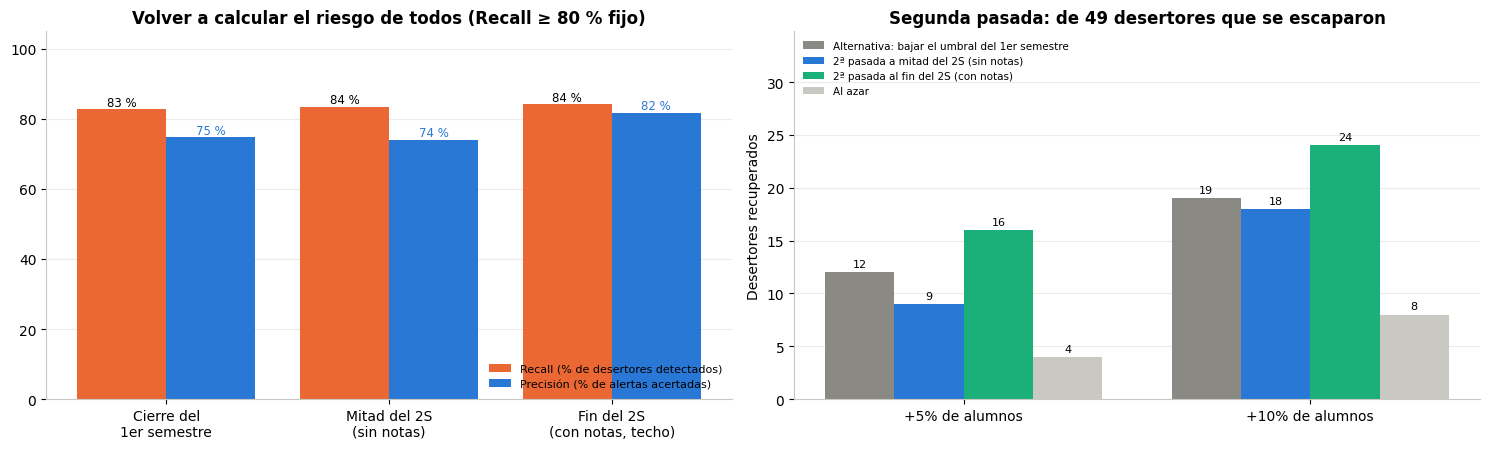

In [76]:
# Gráficos del experimento
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

ax = axes[0]
etiquetas = ["Cierre del\n1er semestre", "Mitad del 2S\n(sin notas)", "Fin del 2S\n(con notas, techo)"]
x = np.arange(3)
ax.bar(x - 0.2, tabla_2S["Recall"] * 100, width=0.4, color=NARANJA, label="Recall (% de desertores detectados)")
ax.bar(x + 0.2, tabla_2S["Precision"] * 100, width=0.4, color=AZUL, label="Precisión (% de alertas acertadas)")
for xi, r, p in zip(x, tabla_2S["Recall"] * 100, tabla_2S["Precision"] * 100):
    ax.text(xi - 0.2, r + 1, f"{r:.0f} %", ha="center", fontsize=8.5)
    ax.text(xi + 0.2, p + 1, f"{p:.0f} %", ha="center", fontsize=8.5, color=AZUL)
ax.set_xticks(x, etiquetas); ax.set_ylim(0, 105); ax.grid(axis="x", visible=False)
ax.set_title("Volver a calcular el riesgo de todos (Recall ≥ 80 % fijo)")
ax.legend(frameon=False, fontsize=8, loc="lower right")

ax = axes[1]
columnas = ["Alternativa: bajar el umbral del 1er semestre", "2ª pasada a mitad del 2S (sin notas)",
            "2ª pasada al fin del 2S (con notas)", "Al azar"]
colores = [GRIS, AZUL, VERDE, "#c9c8c2"]
x = np.arange(len(segunda_pasada))
for k, (col, color) in enumerate(zip(columnas, colores)):
    ax.bar(x + (k - 1.5) * 0.2, segunda_pasada[col], width=0.2, color=color, label=col)
    for xi, v in zip(x + (k - 1.5) * 0.2, segunda_pasada[col]):
        ax.text(xi, v + 0.5, f"{v}", ha="center", fontsize=8)
ax.set_xticks(x, segunda_pasada.index); ax.grid(axis="x", visible=False)
ax.set_ylabel("Desertores recuperados"); ax.set_title(f"Segunda pasada: de {int(y_sin_alerta.sum())} desertores que se escaparon")
ax.set_ylim(0, segunda_pasada.values.max() * 1.45)
ax.legend(frameon=False, fontsize=7.5, loc="upper left")
plt.tight_layout()
plt.show()

Experimento de la mitad del 2º semestre, conclusiones:
- Esperar a la mitad del 2º semestre (sin notas) no detecta más. Con el mismo criterio de Recall ≥ 80 %, la Precisión queda casi igual (75 % y 73 %). Saber en cuántas materias se inscribió y a cuántas evaluaciones se presentó repite casi lo mismo que ya decía el 1er semestre.
- Con las notas finales del 2º semestre (el techo) el modelo mejora: con el mismo Recall, la Precisión sube a 82 %, o sea menos falsas alarmas. Pero esa información llega al final del año: muchos de esos alumnos ya se fueron y ya no hay tiempo de intervenir. Como alerta temprana no sirve.
- Segunda pasada sobre los 52 desertores que se escaparon:
  - Con un cupo extra del 5 % o del 10 % de los alumnos, la segunda pasada a mitad del 2S recupera lo mismo que bajar el umbral del 1er semestre (12 contra 12 y 20 contra 20).
  - Con las notas finales del 2S se recuperarían entre 16 y 27, pero otra vez: es información que llega tarde.
- ¿Y los que abandonan antes de empezar el 2º semestre? Para ellos la segunda pasada no llega a tiempo. Por eso la alerta tiene que darse al cierre del 1er semestre, y un control a mitad del 2S solo sirve como revisión complementaria (por ejemplo, alumnos inscriptos que no se presentan a ninguna evaluación).

- Conclusión: el techo lo ponen los datos disponibles. Mientras el dataset no tenga notas parciales o asistencia, asi como datos relevantes del abandono de estudiantes bien perfilados no habra forma de aumentar la tasa de deteccion. 
Se concluye la mejor estrategia es una sola alerta al cierre del 1er semestre y, si la institución tiene más capacidad de tutorías, bajar el umbral en lugar de agregar un segundo modelo.

## 19. Observación: metodología descartada (modelo en cascada)
Metodología descartada por falta de datos, a considerar para la mejora del modelo.

Análisis del Modelo en Cascada y Limitantes:
- Se pensó en la posibilidad de realizar un modelo en cascada para detectar las deserciones que escapan al modelo principal; sin embargo, se desistió de su implementación debido a las limitantes en el conjunto de datos.
 Esto no significa que no se pueda lograr en el futuro; queda en manos de las personas interesadas y de las instituciones educativas recopilar la información útil y definir qué otros datos serían necesarios para implementar
   dicho modelo.
- Limitante principal: La información disponible sobre los perfiles que no fueron detectados no tiene un peso estadístico significativo con el target. 
  * Actualmente, no hay forma de que el modelo pueda predecir que un alumno de 20 años, becario y con buen promedio de calificaciones, vaya a desertar. 
  * No obstante, esto también representa un llamado de atención sobre las motivaciones de abandono en esta clase de estudiantes. 
  * Se puede hipotetizar que su deserción podría estar motivada por un cambio de intereses, problemas personales o porque la institución no cumple con sus expectativas.
- Conclusión: Se determina que el modelo en cascada no es viable con los datos actuales y que se debería trabajar en la recolección de variables adicionales para su implementación. La mejora en la calidad de los datos no 
solo optimizaría la predicción de la tasa de deserción, sino que también serviría para identificar falencias estructurales dentro de las instituciones educativas y así mejorar la calidad de la educación.

## 20. Conclusiones generales
- Con la información disponible al cierre del 1er semestre se detecta a 8 de cada 10 alumnos que abandonan (Recall 81,7 %), con 3 de cada 4 alertas acertadas. Se supera la meta del 70 % sin un exceso de falsas alarmas.
- Los seis modelos rinden casi igual. XGBoost quedó como modelo principal por su PR-AUC y la Regresión Logística como alternativa más fácil de explicar.
- El ajuste del umbral fue lo que más mejoró la detección; los hiperparámetros cambiaron poco.
- De las alertas, el 75 % son alumnos que abandonaron y el 14 % alumnos con señales de riesgo. Solo el 11 % son falsas alarmas sin ninguna señal.
- Las señales más fuertes son las notas del 1er semestre y la situación de pago. Los desertores que no muestran ninguna de las dos, en especial becarios con buenas notas, no se pueden detectar con estos datos.
- Acompañar a todos los alumnos con alerta con tutorías grupales cuesta un 10,5 % más de horas docentes. El efecto real sobre el abandono habría que medirlo con un piloto.